<a href="https://colab.research.google.com/github/alwaleed-alharbi/call-duration-analysis/blob/main/DataViz_Course_Project_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Data Visualization — Graded Course Project
## BrewLine Café: From Raw Transactions to a Data Story

| | |
|---|---|
| **Course** | Data Visualization |
| **Weight** | Course project (100 points) |
| **Format** | Individual work, one `.ipynb` file |
| **Estimated effort** | 8 – 10 hours |
| **Student name / ID** | *fill in the next cell* |

---

### 🎯 Scenario
**BrewLine** is a fast-growing café chain with **12 stores in 6 Saudi cities**. The management team has handed you
**two years (2023 – 2024) of raw point-of-sale data**. The data was exported straight from the till system, so it is
**messy** — it contains duplicates, missing values, inconsistent spelling and data-entry errors.

Your job is to act as the chain's data analyst: **clean** the data, **describe** it statistically, **visualize** it
with static and interactive charts, **analyze** its time series, **explore** an image dataset used for the chain's
marketing, and finally **communicate** three actionable insights to management.

### 🧮 Grading rubric (100 points)
| Part | Content | Points |
|---|---|---|
| 1 | Data understanding, cleaning & feature engineering | **12** |
| 2 | Descriptive statistics & hypothesis testing | **10** |
| 3 | Visualizing numeric, categorical & ordinal data | **14** |
| 4 | Advanced Matplotlib / Seaborn plotting | **14** |
| 5 | Exploratory data analysis: correlation & PCA | **12** |
| 6 | Time-series visualization, decomposition & forecasting | **14** |
| 7 | Interactive visualization with Plotly | **14** |
| 8 | Data storytelling & reflection | **10** |
| | **Total** | **100** |

**Figure quality criteria (applied inside every plotting task):** correct chart type for the data · title, axis labels with
units · readable fonts · legend only when needed · colour-blind-safe palette · no overplotting / chart junk · sensible
ordering of categories.

**Adjustments:** up to **−5** if the notebook does not run top-to-bottom (*Kernel → Restart & Run All*) or contains
leftover `YOUR CODE HERE` stubs; up to **+3** bonus for outstanding creativity or an extra insightful visualization
(clearly labelled *BONUS*).

### 📜 Rules
1. Use only the libraries listed in the *Setup* cell (all were used in the course labs).
2. **Do not edit** the data-generation cell or cells marked 🔒 *given*.
3. Every plotting task needs a **title, axis labels and readable ticks**. Answers to "interpret" questions must be
   written in the Markdown cell right under the task and must **cite numbers from your output**.
4. Keep the variable names in the *naming contract* below — the instructor's auto-checks rely on them.
5. Work must be your own. Copying code from classmates or generated text without understanding it is academic misconduct.
   You may consult the course notebooks, library documentation and Stack Overflow — cite any non-trivial snippet in a comment.

### 🏷️ Naming contract (used by the 🔒 check cells)
| Variable | Meaning | Defined in |
|---|---|---|
| `tx`, `stores` | raw transactions / stores tables | 1.1 |
| `column_types` | `dict` column → type | 1.2 |
| `df` | **final clean & enriched** transactions DataFrame | 1.3 – 1.6 |
| `rev_stats` | `pd.Series` of revenue statistics | 2.1 |
| `p_ttest`, `p_anova` | p-values (floats) | 2.4 |
| `pca` | `sklearn` PCA fitted with **all** components | 5.2 |
| `daily` | daily revenue `pd.Series` with a daily `DatetimeIndex` | 6.1 |
| `forecast_hw`, `forecast_naive`, `metrics` | 28-day forecasts & error table | 6.5 |

### 📦 Submission
Run *Kernel → Restart & Run All*, make sure no cell errors, then submit **this `.ipynb` file** (with outputs) **and** the
`outputs/` folder it creates (saved figures + HTML). Late policy: as announced by the instructor.

## 0 · Setup  🔒 *(given — run, do not edit)*

In [57]:
# ✏️ Fill in your details
STUDENT_NAME = Alwaleed Brahem Alharbi
STUDENT_ID = 472110527

SyntaxError: invalid syntax (4059299804.py, line 2)

In [58]:
# 🔒 GIVEN — libraries and global settings
# pip install pandas numpy matplotlib seaborn plotly scipy scikit-learn statsmodels scikit-image opencv-python
import os, sys, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats
from IPython.display import display, Markdown

if "google.colab" not in sys.modules:                 # lightweight Plotly renderer for Jupyter / VS Code
    pio.renderers.default = "plotly_mimetype+notebook_connected"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
os.makedirs("outputs", exist_ok=True)                 # all saved figures must go here

SEED = 2026
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTH_ORDER = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
print("Setup OK — pandas", pd.__version__, "| seaborn", sns.__version__)

Setup OK — pandas 2.2.3 | seaborn 0.13.2


### 🔒 Data generation *(given — do not edit)*
The function below simulates the BrewLine point-of-sale export and writes two CSV files to `data/`.
Prices are in **Saudi riyals (SAR)**. Weekend in Saudi Arabia = **Friday & Saturday**.

| File | Columns |
|---|---|
| `brewline_transactions.csv` | `transaction_id, date, store_id, city, category, product, quantity, unit_price, discount, customer_segment, payment_method, customer_age, prep_time_min, rating` |
| `brewline_stores.csv` | `store_id, city, lat, lon, store_size` |

`rating` is the customer satisfaction score from **1 (poor) to 5 (excellent)** and `prep_time_min` the minutes needed to prepare the order.

In [59]:
# 🔒 GIVEN — synthetic, reproducible data generator (do not edit)
def make_brewline_data(seed=2026, n_rows=12000, out_dir="data"):
    rng = np.random.default_rng(seed)
    os.makedirs(out_dir, exist_ok=True)

    # ---------- stores ----------
    city_ll = {"Riyadh": (24.7136, 46.6753), "Jeddah": (21.4858, 39.1925), "Dammam": (26.4207, 50.0888),
               "Mecca": (21.3891, 39.8579), "Medina": (24.5247, 39.5692), "Abha": (18.2164, 42.5053)}
    store_cities = ["Riyadh"] * 4 + ["Jeddah"] * 3 + ["Dammam"] * 2 + ["Mecca", "Medina", "Abha"]
    stores = pd.DataFrame({"store_id": [f"S{i:02d}" for i in range(1, 13)], "city": store_cities})
    stores["lat"] = stores.city.map(lambda c: city_ll[c][0]) + rng.normal(0, 0.04, 12)
    stores["lon"] = stores.city.map(lambda c: city_ll[c][1]) + rng.normal(0, 0.04, 12)
    stores["store_size"] = rng.choice(["Small", "Medium", "Large"], 12, p=[.3, .45, .25])
    size_w = stores.store_size.map({"Small": .6, "Medium": 1.0, "Large": 1.7}).to_numpy()
    city_w = stores.city.map({"Riyadh": 1.3, "Jeddah": 1.1, "Dammam": .9, "Mecca": .8, "Medina": .7, "Abha": .5}).to_numpy()
    sp = size_w * city_w; sp = sp / sp.sum()

    # ---------- dates: growth trend + weekend peak + yearly seasonality ----------
    dates = pd.date_range("2023-01-01", "2024-12-31", freq="D")
    t = np.arange(len(dates)); dow = dates.dayofweek.to_numpy()
    w = (1 + 0.0010 * t) * np.where(np.isin(dow, [4, 5]), 1.35, 1.0) \
        * (1 + 0.12 * np.sin(2 * np.pi * (dates.dayofyear.to_numpy() - 30) / 365.25))
    date = pd.to_datetime(rng.choice(dates.to_numpy(), size=n_rows, p=w / w.sum()))
    month, dow_r = date.month.to_numpy(), date.dayofweek.to_numpy()
    store_idx = rng.choice(12, size=n_rows, p=sp)

    # ---------- category / product (cold drinks boom in summer) ----------
    cats = ["Coffee", "Tea", "Cold Drinks", "Bakery", "Merchandise"]
    catalog = {"Coffee": [("Espresso", 12), ("Latte", 18), ("Cappuccino", 17), ("Flat White", 19), ("Arabic Coffee", 10)],
               "Tea": [("Karak Tea", 9), ("Green Tea", 11), ("Mint Tea", 10)],
               "Cold Drinks": [("Iced Latte", 20), ("Cold Brew", 22), ("Lemonade", 14), ("Iced Tea", 13)],
               "Bakery": [("Croissant", 10), ("Date Maamoul", 8), ("Cheesecake", 24), ("Muffin", 11)],
               "Merchandise": [("Tumbler", 55), ("Coffee Beans 250g", 48), ("Mug", 35)]}
    p_winter = np.cumsum([.40, .15, .15, .24, .06]); p_summer = np.cumsum([.30, .10, .38, .17, .05])
    u = rng.random(n_rows); summer = np.isin(month, [6, 7, 8, 9])
    cat_idx = np.minimum(np.where(summer, np.searchsorted(p_summer, u), np.searchsorted(p_winter, u)), 4)
    product = np.empty(n_rows, dtype=object); base = np.zeros(n_rows)
    for ci, c in enumerate(cats):
        idx = np.where(cat_idx == ci)[0]; items = catalog[c]
        pick = rng.integers(0, len(items), len(idx))
        product[idx] = [items[k][0] for k in pick]; base[idx] = [items[k][1] for k in pick]

    # ---------- customers, prices, quantities ----------
    seg = rng.choice(["Regular", "New", "Loyalty", "Corporate"], n_rows, p=[.45, .25, .22, .08])
    lam = np.where(np.isin(dow_r, [4, 5]), 0.75, 0.40) + np.where(seg == "Corporate", 1.8, 0.0)
    qty = 1 + rng.poisson(lam); qty = np.where(cat_idx == 4, np.minimum(qty, 3), qty)
    price = np.round(base * np.where(date.year == 2024, 1.04, 1.0) * rng.normal(1, 0.03, n_rows), 2)
    disc = np.zeros(n_rows)
    for s, (vals, pr) in {"Loyalty": ([0, .05, .10], [.3, .4, .3]), "New": ([0, .10, .20], [.5, .3, .2]),
                          "Regular": ([0, .05], [.8, .2]), "Corporate": ([0, .05], [.8, .2])}.items():
        m = seg == s; disc[m] = rng.choice(vals, m.sum(), p=pr)
    pay = rng.choice(["Card", "Cash", "Mobile Wallet", "Apple Pay"], n_rows, p=[.40, .15, .25, .20])
    age = np.clip(rng.normal(np.where(seg == "Corporate", 40, 31), 9), 16, 70).round()
    prep = np.clip(2 + 1.1 * qty + np.where(cat_idx == 3, -1.0, 0.0) + np.where(np.isin(dow_r, [4, 5]), .6, 0.0)
                   + rng.normal(0, .8, n_rows), 1, None).round(1)
    rating = np.clip(np.round(4.7 - 0.12 * prep + rng.normal(0, .7, n_rows)), 1, 5)

    df = pd.DataFrame({"date": date, "store_id": stores.store_id.to_numpy()[store_idx],
                       "city": stores.city.to_numpy()[store_idx], "category": np.array(cats)[cat_idx],
                       "product": product, "quantity": qty, "unit_price": price, "discount": disc,
                       "customer_segment": seg, "payment_method": pay, "customer_age": age,
                       "prep_time_min": prep, "rating": rating})
    df = df.sort_values("date").reset_index(drop=True)
    df.insert(0, "transaction_id", [f"T{i:06d}" for i in range(1, len(df) + 1)])
    df["date"] = df["date"].dt.strftime("%Y-%m-%d")

    # ---------- make it messy ----------
    for col, frac in [("customer_age", .08), ("rating", .12), ("payment_method", .03)]:
        df.loc[rng.random(len(df)) < frac, col] = np.nan
    m = rng.random(len(df)) < .06; df.loc[m, "city"] = df.loc[m, "city"].str.upper()
    m = rng.random(len(df)) < .05; df.loc[m, "city"] = " " + df.loc[m, "city"].str.lower() + " "
    m = rng.random(len(df)) < .04; df.loc[m, "category"] = df.loc[m, "category"].str.lower() + " "
    o = rng.choice(len(df), 10, replace=False); df.loc[o, "unit_price"] = (df.loc[o, "unit_price"] * 10).round(2)
    o = rng.choice(len(df), 6, replace=False);  df.loc[o, "quantity"] = rng.integers(100, 300, 6)
    df = pd.concat([df, df.sample(80, random_state=seed)]).sample(frac=1, random_state=seed).reset_index(drop=True)

    df.to_csv(f"{out_dir}/brewline_transactions.csv", index=False)
    stores.round(5).to_csv(f"{out_dir}/brewline_stores.csv", index=False)
    return df.shape, stores.shape

print(make_brewline_data(seed=SEED))

((12080, 14), (12, 5))


---
# Part 1 · Data Understanding, Cleaning & Feature Engineering  *(12 pts)*
*Course topics: data types, data scrubbing, data transformation.*

### Task 1.1 — Load and inspect  *(2 pts)*
1. Load both CSV files into `tx` and `stores` (`pd.read_csv`).
2. Show the shape, the first rows, `.info()` and `.describe(include="all")` of `tx`.
3. Build a DataFrame `missing` with the **count and percentage** of missing values per column (only columns with missing values).
4. Print the number of fully duplicated rows.

In [60]:
# YOUR CODE HERE
tx = pd.read_csv("data/brewline_transactions.csv", delimiter=",")
stores = pd.read_csv("data/brewline_stores.csv", delimiter=",")

print(tx.shape)
display(tx.head())
display(tx.info())
display(tx.describe(include="all"))

missing = pd.DataFrame({"count": tx.isna().sum(),
                        "percentage": tx.isna().sum() / len(tx) * 100})
missing = missing[missing["count"] > 0]
display(missing)

print("Number of fully duplicated rows:", tx.duplicated().sum())

(12080, 14)


,transaction_id,date,store_id,city,category,product,quantity,unit_price,discount,customer_segment,payment_method,customer_age,prep_time_min,rating
0,T000519,2023-02-17,S09,Dammam,Bakery,Cheesecake,2,24.270,0.100,New,Mobile Wallet,28.000,5.100,NaN
1,T007649,2024-05-17,S05,Jeddah,Coffee,Cappuccino,1,18.900,0.000,New,Card,38.000,2.400,5.000
2,T003009,2023-08-05,S09,Dammam,Coffee,Arabic Coffee,4,10.420,0.000,Corporate,Apple Pay,33.000,7.000,4.000
3,T007102,2024-04-20,S09,Dammam,Cold Drinks,Iced Tea,1,13.230,0.050,Loyalty,Cash,35.000,4.900,5.000
4,T002124,2023-06-08,S10,Mecca,Bakery,Muffin,1,10.860,0.000,New,Mobile Wallet,43.000,2.300,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12080 entries, 0 to 12079
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    12080 non-null  object 
 1   date              12080 non-null  object 
 2   store_id          12080 non-null  object 
 3   city              12080 non-null  object 
 4   category          12080 non-null  object 
 5   product           12080 non-null  object 
 6   quantity          12080 non-null  int64  
 7   unit_price        12080 non-null  float64
 8   discount          12080 non-null  float64
 9   customer_segment  12080 non-null  object 
 10  payment_method    11706 non-null  object 
 11  customer_age      11084 non-null  float64
 12  prep_time_min     12080 non-null  float64
 13  rating            10622 non-null  float64
dtypes: float64(5), int64(1), object(8)
memory usage: 1.3+ MB


None

,transaction_id,date,store_id,city,category,product,quantity,unit_price,discount,customer_segment,payment_method,customer_age,prep_time_min,rating
count,12080,12080,12080,12080,12080,12080,"12,080.000","12,080.000","12,080.000",12080,11706,"11,084.000","12,080.000","10,622.000"
unique,12000,731,12,18,10,19,NaN,NaN,NaN,4,4,NaN,NaN,NaN
top,T010815,2024-06-21,S08,Riyadh,Coffee,Cappuccino,NaN,NaN,NaN,Regular,Card,NaN,NaN,NaN
freq,2,39,1543,4139,4284,933,NaN,NaN,NaN,5447,4654,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,1.742,16.728,0.033,NaN,NaN,32.027,3.828,4.199
std,NaN,NaN,NaN,NaN,NaN,NaN,4.299,9.780,0.052,NaN,NaN,9.001,1.441,0.708
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000,7.280,0.000,NaN,NaN,16.000,1.000,1.000
25%,NaN,NaN,NaN,NaN,NaN,NaN,1.000,10.590,0.000,NaN,NaN,26.000,2.800,4.000
50%,NaN,NaN,NaN,NaN,NaN,NaN,1.000,13.800,0.000,NaN,NaN,32.000,3.700,4.000
75%,NaN,NaN,NaN,NaN,NaN,NaN,2.000,19.550,0.050,NaN,NaN,38.000,4.700,5.000


,count,percentage
payment_method,374,3.096
customer_age,996,8.245
rating,1458,12.070


Number of fully duplicated rows: 80


### Task 1.2 — Classify the variables  *(1 pt)*
Create a dictionary `column_types` that maps **every column of `tx`** to one of
`"identifier"`, `"datetime"`, `"nominal"`, `"ordinal"`, `"discrete"`, `"continuous"`.
Add a one-line comment for any column you found debatable.

In [61]:
column_types = {
    "transaction_id": "identifier",
    "date": "datetime",
    "store_id": "nominal",
    "city": "nominal",
    "category": "nominal",
    "product": "nominal",
    "quantity": "discrete",
    "unit_price": "continuous",
    "discount": "continuous",
    "customer_segment": "nominal",
    "payment_method": "nominal",
    "customer_age": "discrete",
    "prep_time_min": "continuous",
    "rating": "ordinal",
}

### Task 1.3 — Standardise formats and remove duplicates  *(2 pts)*
Work on a **copy**: `df = tx.copy()`. Then
* convert `date` to `datetime64`;
* strip white-space and fix the capitalisation of `city` and `category` (e.g. `" riyadh "`, `"RIYADH"` → `"Riyadh"`; `"coffee "` → `"Coffee"`) and strip `product`, `customer_segment`, `payment_method`;
* print `df["city"].unique()` and `df["category"].unique()` to prove the fix;
* drop duplicated transactions (same `transaction_id`) and report how many rows were removed.

In [62]:
# YOUR CODE HERE
df = tx.copy()

df["date"] = pd.to_datetime(df["date"])

# remove white-space and fix the capitalisation
for c in ["city", "category", "product", "customer_segment", "payment_method"]:
    df[c] = df[c].str.strip()
df["city"] = df["city"].str.title()
df["category"] = df["category"].str.title()

print(df["city"].unique())
print(df["category"].unique())

# drop duplicated transactions
n_before = df.shape[0]
df = df.drop_duplicates(subset="transaction_id")
df = df.reset_index(drop=True)
print("Number of removed rows:", n_before - df.shape[0])

['Dammam' 'Jeddah' 'Mecca' 'Riyadh' 'Medina' 'Abha']
['Bakery' 'Coffee' 'Cold Drinks' 'Tea' 'Merchandise']
Number of removed rows: 80


### Task 1.4 — Handle missing values  *(2 pts)*
Choose and **justify (in a code comment)** a strategy per column:
* `customer_age` → impute with the **median age of the same `customer_segment`**;
* `payment_method` → fill with the label `"Unknown"` (do not guess a payment method);
* `rating` → impute with the **median rating of the same `category`** and convert to integer.

Afterwards, print the remaining number of missing values (must be 0 for these three columns).

In [63]:
# YOUR CODE HERE
# customer_age: median age of the same customer_segment (the median is not affected by extreme ages)
for seg in df["customer_segment"].unique():
    median_age = df.loc[df["customer_segment"] == seg, "customer_age"].median()
    df.loc[(df["customer_segment"] == seg) & (df["customer_age"].isna()), "customer_age"] = median_age

# payment_method: we cannot guess how the customer paid, so we use the label "Unknown"
df["payment_method"] = df["payment_method"].fillna("Unknown")

# rating: ordinal data, so we use the median (not the mean) of the same category
for cat in df["category"].unique():
    median_rating = df.loc[df["category"] == cat, "rating"].median()
    df.loc[(df["category"] == cat) & (df["rating"].isna()), "rating"] = median_rating
df["rating"] = df["rating"].round().astype(int)

print(df[["customer_age", "payment_method", "rating"]].isna().sum())

customer_age      0
payment_method    0
rating            0
dtype: int64


### Task 1.5 — Detect and treat outliers  *(2 pts)*
Some prices were typed with an extra zero and some quantities contain typing errors.
1. **`unit_price`**: for each `product` flag values outside `[Q1 − 3·IQR, Q3 + 3·IQR]` (extreme-outlier rule, computed **per product**).
2. **`quantity`**: flag values `> 20` (domain rule — nobody buys 100 coffees at one till).
3. Show a box plot (or strip plot) of `unit_price` for the flagged products **before** removal, print how many rows are flagged, then **remove** them and reset the index.

Price outliers: 10
Quantity outliers: 6
Total flagged rows: 16


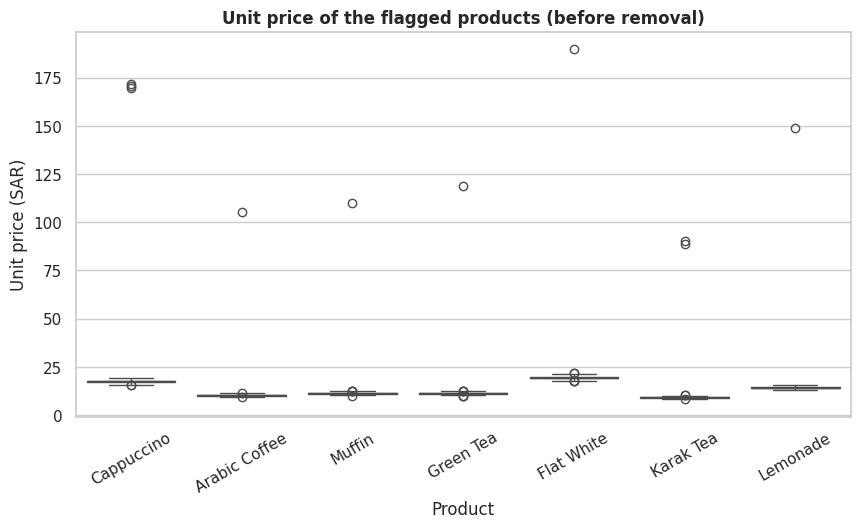

Rows after removal: 11984


In [64]:
# YOUR CODE HERE
# 1. unit_price: extreme outliers per product
price_flag = pd.Series(False, index=df.index)
for p in df["product"].unique():
    prices = df.loc[df["product"] == p, "unit_price"]
    Q1, Q3 = np.percentile(prices, [25, 75])
    IQR = Q3 - Q1
    outside = (prices < Q1 - 3 * IQR) | (prices > Q3 + 3 * IQR)
    price_flag[prices.index[outside]] = True

# 2. quantity: more than 20 is a typing error
qty_flag = df["quantity"] > 20

flag = price_flag | qty_flag
print("Price outliers:", price_flag.sum())
print("Quantity outliers:", qty_flag.sum())
print("Total flagged rows:", flag.sum())

# box plot before removal (only for the flagged products)
flagged_products = df.loc[price_flag, "product"].unique()
plt.figure(figsize=(10, 5))
sns.boxplot(x="product", y="unit_price", data=df[df["product"].isin(flagged_products)])
plt.title("Unit price of the flagged products (before removal)")
plt.xlabel("Product")
plt.ylabel("Unit price (SAR)")
plt.xticks(rotation=30)
plt.show()

# remove the outliers
df = df[~flag]
df = df.reset_index(drop=True)
print("Rows after removal:", df.shape[0])

### Task 1.6 — Feature engineering and merge  *(3 pts)*
Add the following columns to `df`:

| New column | Definition |
|---|---|
| `revenue` | `quantity × unit_price × (1 − discount)`, rounded to 2 decimals |
| `year`, `month` (1–12), `month_name`, `year_month` (text like `"2023-04"`), `day_of_week` (name) | from `date` |
| `is_weekend` | `True` for **Friday and Saturday** |
| `age_group` | `pd.cut` of `customer_age` into `"<25"`, `"25-34"`, `"35-44"`, `"45+"` |

Then **merge** `store_size`, `lat`, `lon` from `stores` on `store_id` (left join), and save the clean table to `outputs/brewline_clean.csv`.

In [65]:
# YOUR CODE HERE
df["revenue"] = (df["quantity"] * df["unit_price"] * (1 - df["discount"])).round(2)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["year_month"] = df["date"].dt.strftime("%Y-%m")
df["day_of_week"] = df["date"].dt.day_name()

df["is_weekend"] = df["day_of_week"].isin(["Friday", "Saturday"])

df["age_group"] = pd.cut(df["customer_age"], bins=[0, 25, 35, 45, 200], right=False,
                         labels=["<25", "25-34", "35-44", "45+"])

# merge with the stores table
df = df.merge(stores[["store_id", "store_size", "lat", "lon"]], on="store_id", how="left")

df.to_csv("outputs/brewline_clean.csv", index=False)
display(df.head())

,transaction_id,date,store_id,city,category,product,quantity,unit_price,discount,customer_segment,payment_method,customer_age,prep_time_min,rating,revenue,year,month,month_name,year_month,day_of_week,is_weekend,age_group,store_size,lat,lon
0,T000519,2023-02-17,S09,Dammam,Bakery,Cheesecake,2,24.270,0.100,New,Mobile Wallet,28.000,5.100,4,43.690,2023,2,February,2023-02,Friday,True,25-34,Large,26.410,50.070
1,T007649,2024-05-17,S05,Jeddah,Coffee,Cappuccino,1,18.900,0.000,New,Card,38.000,2.400,5,18.900,2024,5,May,2024-05,Friday,True,35-44,Medium,21.511,39.176
2,T003009,2023-08-05,S09,Dammam,Coffee,Arabic Coffee,4,10.420,0.000,Corporate,Apple Pay,33.000,7.000,4,41.680,2023,8,August,2023-08,Saturday,True,25-34,Large,26.410,50.070
3,T007102,2024-04-20,S09,Dammam,Cold Drinks,Iced Tea,1,13.230,0.050,Loyalty,Cash,35.000,4.900,5,12.570,2024,4,April,2024-04,Saturday,True,35-44,Large,26.410,50.070
4,T002124,2023-06-08,S10,Mecca,Bakery,Muffin,1,10.860,0.000,New,Mobile Wallet,43.000,2.300,4,10.860,2023,6,June,2023-06,Thursday,False,35-44,Medium,21.380,39.884


In [66]:
# 🔒 CHECK — Part 1 (given)
assert df["transaction_id"].is_unique, "duplicates still present"
assert df[["customer_age", "rating", "payment_method"]].isna().sum().sum() == 0, "missing values remain"
assert {"revenue", "is_weekend", "year_month", "day_of_week", "age_group", "lat", "lon", "store_size"} <= set(df.columns), "missing engineered columns"
assert df["quantity"].max() <= 20 and df["unit_price"].max() < 100, "outliers remain"
assert set(df["category"].unique()) == {"Coffee", "Tea", "Cold Drinks", "Bakery", "Merchandise"}, "category labels not standardised"
assert set(df["city"].unique()) == {"Riyadh", "Jeddah", "Dammam", "Mecca", "Medina", "Abha"}, "city labels not standardised"
assert set(column_types) == set(tx.columns), "column_types must cover every column of tx"
print("✅ Part 1 checks passed —", len(df), "clean rows")

✅ Part 1 checks passed — 11984 clean rows


---
# Part 2 · Descriptive Statistics & Hypothesis Testing  *(10 pts)*
*Course topic 3: centrality, dispersion, distributions, p-values.*

### Task 2.1 — Summary statistics of `revenue`  *(2 pts)*
Create the `pd.Series` **`rev_stats`** (rounded to 2 decimals) with the index
`mean, median, mode, range, IQR, variance, std, skewness, kurtosis` (compute the mode on revenue rounded to whole riyals).

In [67]:
rev_stats = None
# YOUR CODE HERE
revenue = df["revenue"]

rev_stats = pd.Series({
    "mean": revenue.mean(),
    "median": revenue.median(),
    "mode": revenue.round().mode()[0],
    "range": revenue.max() - revenue.min(),
    "IQR": np.percentile(revenue, 75) - np.percentile(revenue, 25),
    "variance": np.var(revenue, ddof=1),
    "std": np.std(revenue, ddof=1),
    "skewness": stats.skew(revenue),
    "kurtosis": stats.kurtosis(revenue),
}).round(2)

print(rev_stats)

mean        26.490
median      19.650
mode        10.000
range      175.870
IQR         21.380
variance   464.210
std         21.550
skewness     2.760
kurtosis    10.700
dtype: float64


### Task 2.2 — Group statistics  *(2 pts)*
Build `by_category`: for each `category` the **count, mean, median, std and total (sum)** of `revenue`, sorted by total revenue (descending), rounded to 2 decimals. Display it.

In [68]:
# YOUR CODE HERE
by_category = df.groupby("category")["revenue"].agg(["count", "mean", "median", "std", "sum"])
by_category = by_category.rename(columns={"sum": "total"})
by_category = by_category.sort_values("total", ascending=False).round(2)
display(by_category)

,count,mean,median,std,total
category,,,,,
Coffee,4448,24.570,18.790,15.590,"109,269.580"
Cold Drinks,2684,28.690,22.300,18.490,"77,013.330"
Bakery,2588,22.030,17.520,17.980,"57,017.100"
Merchandise,672,71.650,55.480,37.730,"48,146.790"
Tea,1592,16.320,11.170,9.950,"25,976.280"


### Task 2.3 — Distribution of revenue  *(3 pts)*
Draw **one figure with two side-by-side panels**:
* left: histogram + KDE of `revenue` with **vertical lines for the mean and the median** (labelled in the legend);
* right: the same for `log10(revenue)`.

Then answer: *Is the raw distribution symmetric? What do mean vs. median and the skewness value tell you? Why is the log scale helpful?*

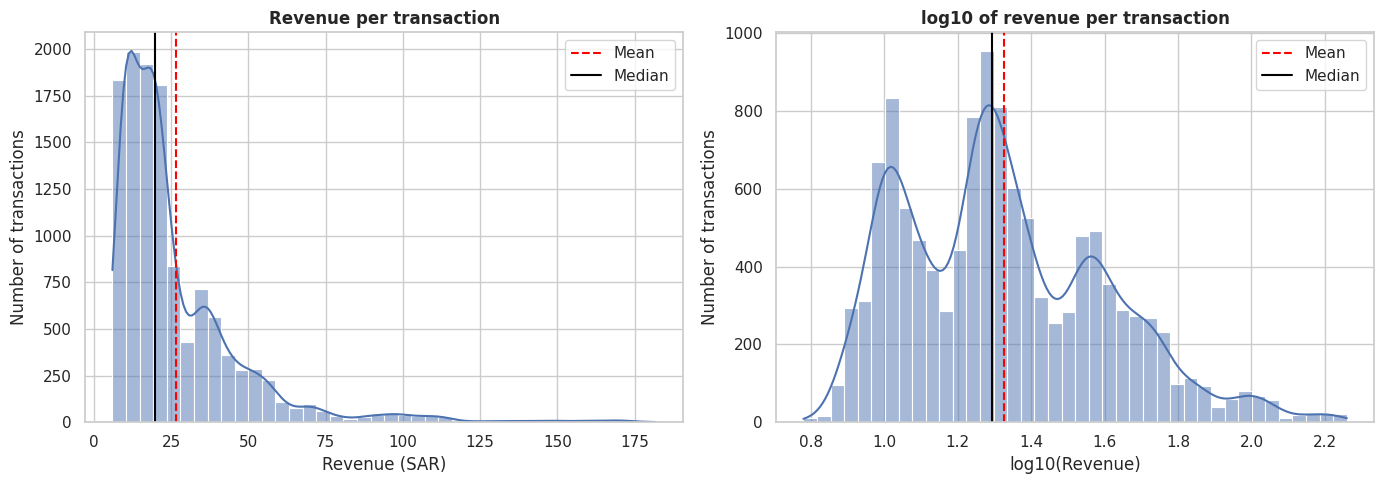

Mean: 26.48723965287049 Median: 19.65
Skewness: 2.7603809277601408 Skewness of log10: 0.5841458821315179


In [69]:
# YOUR CODE HERE
log_revenue = np.log10(df["revenue"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["revenue"], bins=40, kde=True, ax=axes[0])
axes[0].axvline(df["revenue"].mean(), color="red", linestyle="--", label="Mean")
axes[0].axvline(df["revenue"].median(), color="black", linestyle="-", label="Median")
axes[0].set_title("Revenue per transaction")
axes[0].set_xlabel("Revenue (SAR)")
axes[0].set_ylabel("Number of transactions")
axes[0].legend()

sns.histplot(log_revenue, bins=40, kde=True, ax=axes[1])
axes[1].axvline(log_revenue.mean(), color="red", linestyle="--", label="Mean")
axes[1].axvline(log_revenue.median(), color="black", linestyle="-", label="Median")
axes[1].set_title("log10 of revenue per transaction")
axes[1].set_xlabel("log10(Revenue)")
axes[1].set_ylabel("Number of transactions")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Mean:", df["revenue"].mean(), "Median:", df["revenue"].median())
print("Skewness:", stats.skew(df["revenue"]), "Skewness of log10:", stats.skew(log_revenue))

✍️ **Your answer:** *(write 2–4 sentences here — double-click to edit)*

### Task 2.4 — Hypothesis tests  *(3 pts)*
Use `scipy.stats` (significance level α = 0.05).
1. **Welch two-sample t-test**: is the mean `revenue` of **weekend** transactions different from **weekday** transactions? Store the p-value in **`p_ttest`**.
2. **One-way ANOVA**: does mean `revenue` differ across the four `customer_segment`s? Store the p-value in **`p_anova`**.
3. State H₀/H₁, the decision, and a business interpretation for each test. *(Bonus thought: revenue is skewed — would a non-parametric test change the conclusion?)*

In [70]:
p_ttest = None
p_anova = None
# YOUR CODE HERE
weekend = df.loc[df["is_weekend"] == True, "revenue"]
weekday = df.loc[df["is_weekend"] == False, "revenue"]

# H0: the mean revenue of weekend and weekday transactions is equal. H1: it is different.
_, p_ttest = stats.ttest_ind(weekend, weekday, equal_var=False)
print("Weekend mean:", weekend.mean(), "Weekday mean:", weekday.mean())
print("p-value (t-test):", p_ttest)

if p_ttest < 0.05:
    print("We reject null hypothesis")
else:
    print("We fail to reject null hypothesis")

# H0: the mean revenue is equal in the four customer segments. H1: at least one is different.
groups = []
for seg in df["customer_segment"].unique():
    groups.append(df.loc[df["customer_segment"] == seg, "revenue"])

_, p_anova = stats.f_oneway(*groups)
print(df.groupby("customer_segment")["revenue"].mean())
print("p-value (ANOVA):", p_anova)

if p_anova < 0.05:
    print("We reject null hypothesis")
else:
    print("We fail to reject null hypothesis")

_, p_mw = stats.mannwhitneyu(weekend, weekday)
print("p-value (Mann-Whitney):", p_mw)

Weekend mean: 29.841636619058768 Weekday mean: 24.629774406845588
p-value (t-test): 1.94705482134391e-33
We reject null hypothesis
customer_segment
Corporate   52.698
Loyalty     24.065
New         23.086
Regular     24.940
Name: revenue, dtype: float64
p-value (ANOVA): 0.0
We reject null hypothesis
p-value (Mann-Whitney): 3.522831879051952e-49


✍️ **Your answer:** *(write 2–4 sentences here — double-click to edit)*

In [71]:
# 🔒 CHECK — Part 2 (given)
assert isinstance(rev_stats, pd.Series) and {"mean", "median", "mode", "range", "IQR", "variance", "std", "skewness", "kurtosis"} <= set(rev_stats.index)
assert 0 <= float(p_ttest) <= 1 and 0 <= float(p_anova) <= 1
assert abs(rev_stats["mean"] - df["revenue"].mean()) < 0.01
print("✅ Part 2 checks passed")

✅ Part 2 checks passed


---
# Part 3 · Visualizing Numeric, Categorical & Ordinal Data  *(14 pts)*
*Course topic 2: histograms, box/violin plots, scatter & line plots, bar/count plots, pie charts, colour theory.*

Use a **colour-blind-safe palette** throughout (e.g. `sns.color_palette("colorblind")`).

### Task 3.1 — Four numeric views in one figure  *(4 pts)*
Create a `2 × 2` grid (`plt.subplots`) with:
1. **Histogram** of `customer_age` (choose a sensible number of bins);
2. **Box plot** of `unit_price` for each `category` (ordered by number of transactions);
3. **Scatter plot** of `prep_time_min` (x) vs `revenue` (y) on a **random sample of 1 500 rows**, coloured by `category` (use transparency to fight over-plotting);
4. **Line plot** of total monthly revenue (`year_month`) with markers and rotated tick labels.

Every panel needs its own title and axis labels; add one overall `suptitle`.

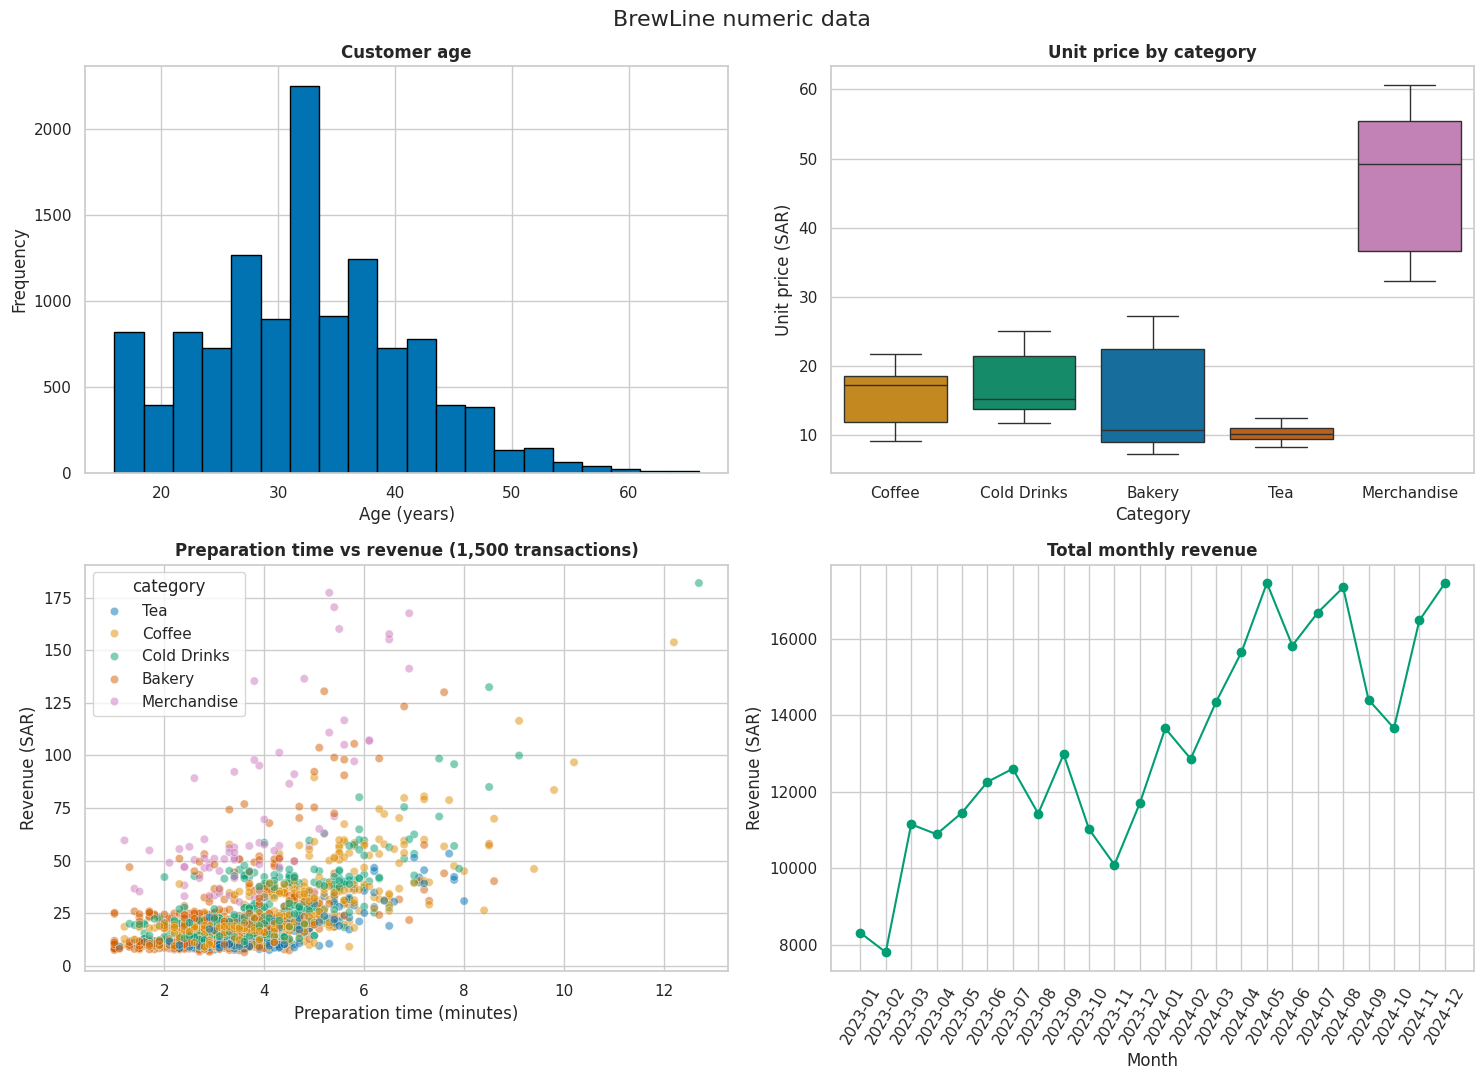

In [72]:
# YOUR CODE HERE
PAL = sns.color_palette("colorblind")

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. histogram
axes[0, 0].hist(df["customer_age"], bins=20, color=PAL[0], edgecolor="black")
axes[0, 0].set_title("Customer age")
axes[0, 0].set_xlabel("Age (years)")
axes[0, 0].set_ylabel("Frequency")

# 2. box plot ordered by number of transactions
order = df["category"].value_counts().index
sns.boxplot(x="category", y="unit_price", data=df, order=order, palette=PAL, hue="category", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Unit price by category")
axes[0, 1].set_xlabel("Category")
axes[0, 1].set_ylabel("Unit price (SAR)")

# 3. scatter plot on a random sample
sample = df.sample(1500, random_state=SEED)
sns.scatterplot(x="prep_time_min", y="revenue", hue="category", palette=PAL, alpha=0.5, data=sample, ax=axes[1, 0])
axes[1, 0].set_title("Preparation time vs revenue (1,500 transactions)")
axes[1, 0].set_xlabel("Preparation time (minutes)")
axes[1, 0].set_ylabel("Revenue (SAR)")

# 4. line plot of monthly revenue
monthly = df.groupby("year_month")["revenue"].sum()
axes[1, 1].plot(monthly.index, monthly.values, marker="o", color=PAL[2])
axes[1, 1].set_title("Total monthly revenue")
axes[1, 1].set_xlabel("Month")
axes[1, 1].set_ylabel("Revenue (SAR)")
axes[1, 1].tick_params(axis="x", rotation=60)

fig.suptitle("BrewLine numeric data", fontsize=16)
plt.tight_layout()
plt.show()

### Task 3.2 — Three categorical views  *(4 pts)*
In a `1 × 3` figure (`figsize≈(18, 5)`) draw:
1. a **count plot** of `category` (horizontal bars, sorted);
2. a **bar chart of mean `revenue` per `payment_method`** with 95 % confidence-interval error bars, bars sorted;
3. a **donut chart** (pie with a hole) of the share of transactions per `customer_segment` with percentage labels.

Store the figure in the variable `fig_cat`.

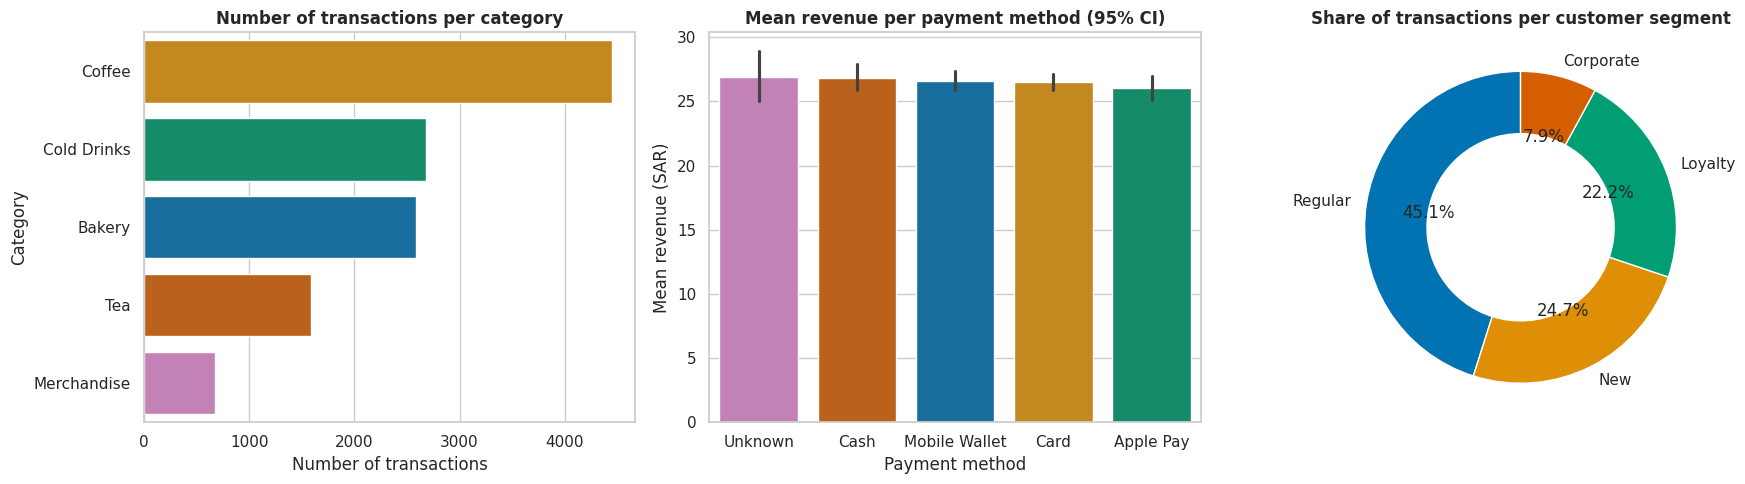

In [73]:
#fig_cat = None
# YOUR CODE HERE
fig_cat, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. count plot (horizontal bars, sorted)
order = df["category"].value_counts().index
sns.countplot(y="category", data=df, order=order, palette=PAL, hue="category", legend=False, ax=axes[0])
axes[0].set_title("Number of transactions per category")
axes[0].set_xlabel("Number of transactions")
axes[0].set_ylabel("Category")

# 2. mean revenue per payment method (sns.barplot draws the 95% confidence interval by default)
order = df.groupby("payment_method")["revenue"].mean().sort_values(ascending=False).index
sns.barplot(x="payment_method", y="revenue", data=df, order=order, palette=PAL, hue="payment_method", legend=False, ax=axes[1])
axes[1].set_title("Mean revenue per payment method (95% CI)")
axes[1].set_xlabel("Payment method")
axes[1].set_ylabel("Mean revenue (SAR)")

# 3. donut chart
seg = df["customer_segment"].value_counts()
axes[2].pie(seg, labels=seg.index, autopct="%1.1f%%", startangle=90, colors=PAL,
            wedgeprops={"width": 0.4})
axes[2].set_title("Share of transactions per customer segment")

plt.tight_layout()
plt.show()

### Task 3.3 — Compare distributions with a violin plot  *(2 pts)*
Draw a **violin plot** of `revenue` for each `customer_segment`, using a **log-scaled y-axis** (`log_scale=True` or `plt.yscale("log")`),
segments **ordered by median revenue**, with the inner box visible. Add a title that states the finding.

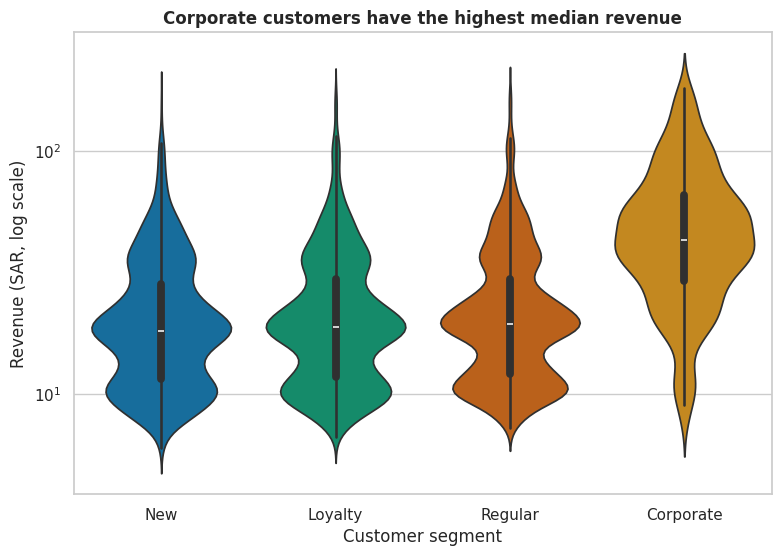

In [74]:
# YOUR CODE HERE
order = df.groupby("customer_segment")["revenue"].median().sort_values().index

plt.figure(figsize=(9, 6))
sns.violinplot(x="customer_segment", y="revenue", data=df, order=order, palette=PAL,
               hue="customer_segment", legend=False, inner="box", log_scale=True)
plt.title(f"{order[-1]} customers have the highest median revenue")
plt.xlabel("Customer segment")
plt.ylabel("Revenue (SAR, log scale)")
plt.show()

### Task 3.4 — Ordinal data: satisfaction ratings  *(2 pts)*
`rating` is **ordinal (1–5)**. Create a **100 % stacked horizontal bar chart** showing the percentage of each rating within every `category`
(`pd.crosstab(..., normalize="index")`). Because the data are ordinal use an **ordered, sequential colour map** (not a qualitative palette), place the legend outside the plot and label the x-axis in %.

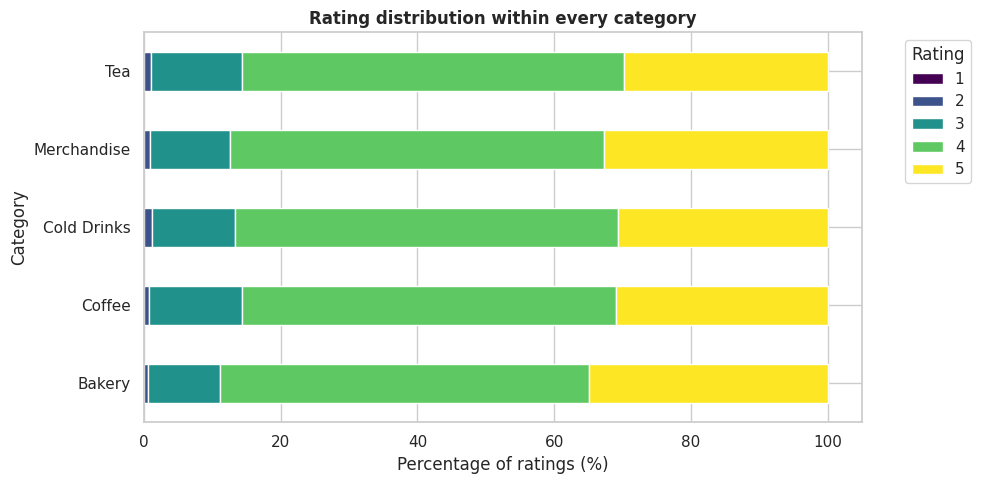

In [75]:
# YOUR CODE HERE
ct = pd.crosstab(df["category"], df["rating"], normalize="index") * 100

# sequential colour map because rating is ordinal
ct.plot(kind="barh", stacked=True, colormap="viridis", figsize=(10, 5))
plt.title("Rating distribution within every category")
plt.xlabel("Percentage of ratings (%)")
plt.ylabel("Category")
plt.legend(title="Rating", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Task 3.5 — Save and justify  *(2 pts)*
1. Save `fig_cat` as **`outputs/fig_3_categorical.png`** at **300 dpi** with a tight bounding box.
2. In 2–3 sentences explain **why your palette is accessible** (colour-vision deficiency, print in grey-scale) and why you used a sequential map for Task 3.4 but a qualitative one elsewhere.

In [76]:
# YOUR CODE HERE
fig_cat.savefig("outputs/fig_3_categorical.png", dpi=300, bbox_inches="tight")

✍️ **Your answer:** *(write 2–4 sentences here — double-click to edit)*

---
# Part 4 · Advanced Plotting with Matplotlib & Seaborn  *(14 pts)*
*Course topic 3 (advanced): subplots/GridSpec, heat-maps, colour maps & colour bars, customisation, combining Matplotlib + Seaborn.*

### Task 4.1 — A GridSpec dashboard  *(4 pts)*
Using `matplotlib.gridspec.GridSpec(2, 3)` build **one figure with three panels of different sizes**:
* **top-left** (1 cell): total revenue per `city`, horizontal bars sorted descending;
* **top-middle + top-right** (2 cells): **average daily revenue per weekday** (first sum revenue per date, then average per weekday, ordered Monday → Sunday). Colour **weekend days differently** from weekdays;
* **bottom row** (all 3 cells): **monthly revenue stacked by `category`** (stacked bars, one bar per `year_month`).

Add a bold `suptitle`, consistent fonts, and make sure nothing overlaps (`tight_layout`/`constrained_layout`).

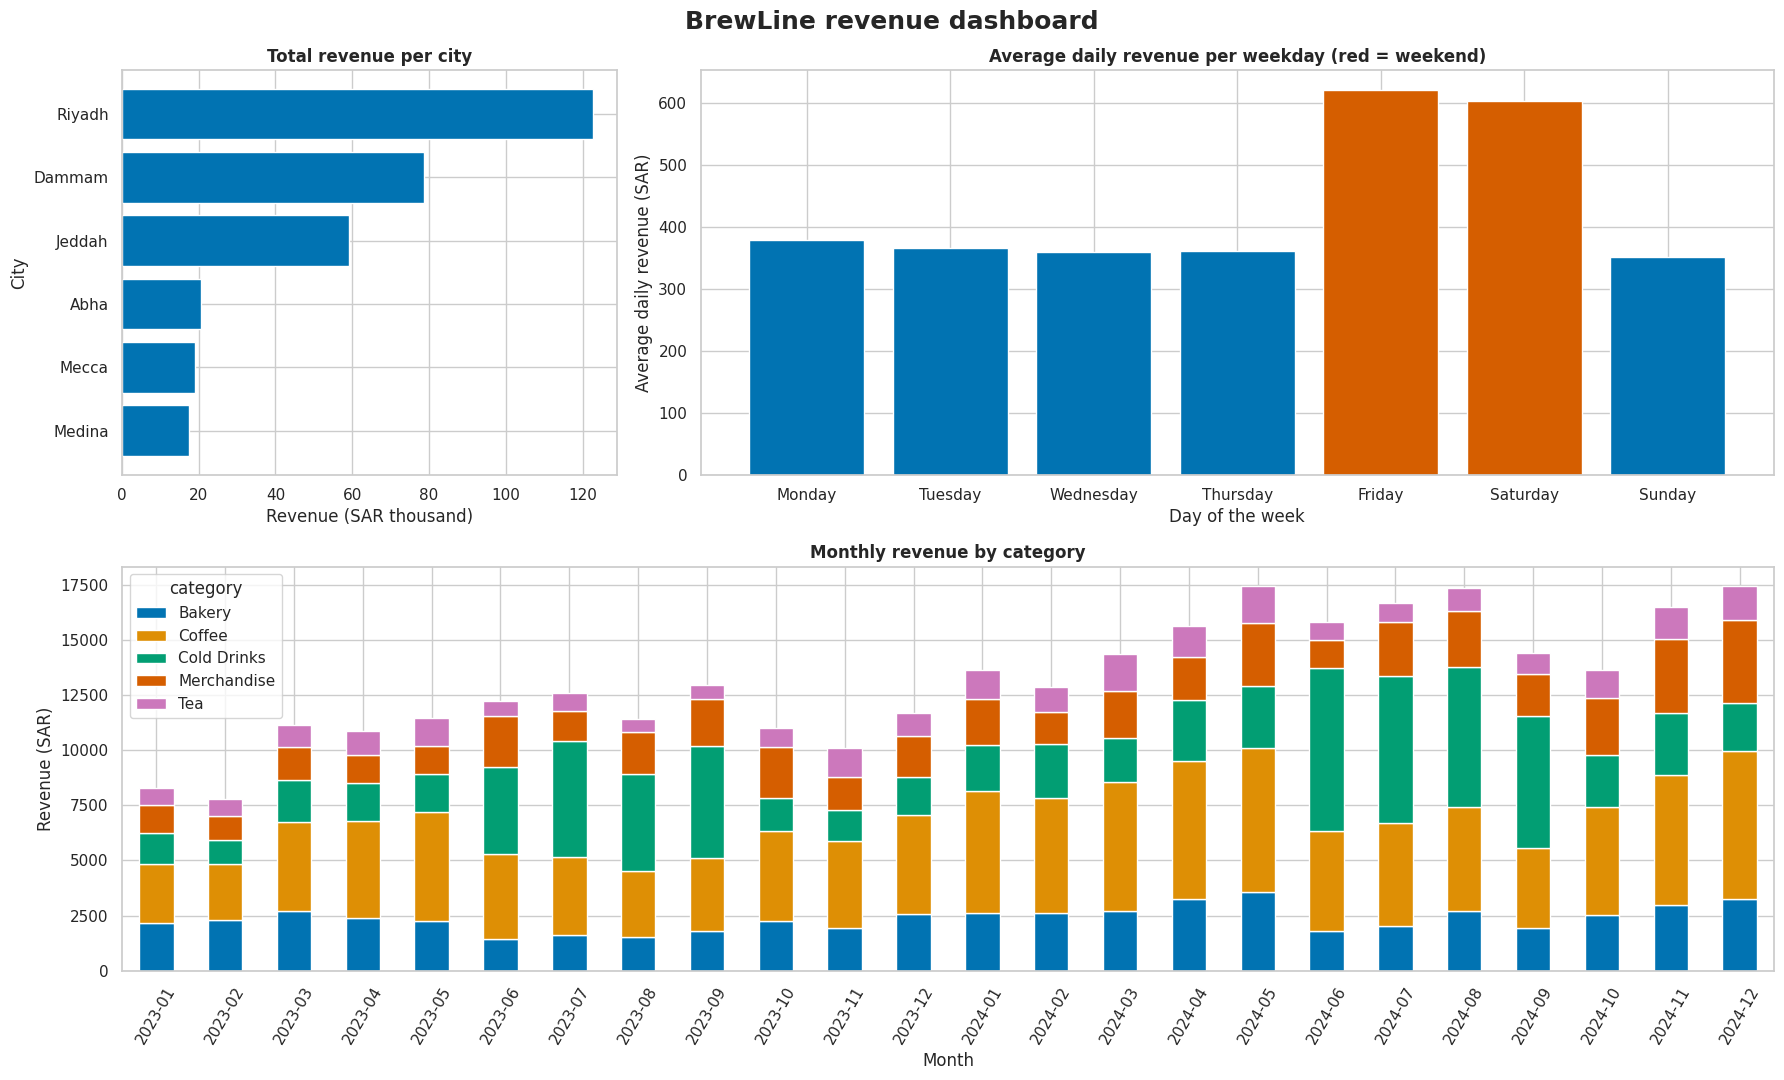

In [77]:
#from matplotlib.gridspec import GridSpec
# YOUR CODE HERE
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(18, 11))
gs = GridSpec(2, 3, figure=fig)

# top-left: total revenue per city
ax1 = fig.add_subplot(gs[0, 0])
city_rev = df.groupby("city")["revenue"].sum().sort_values(ascending=True)
ax1.barh(city_rev.index, city_rev.values / 1000, color=PAL[0])
ax1.set_title("Total revenue per city")
ax1.set_xlabel("Revenue (SAR thousand)")
ax1.set_ylabel("City")

# top-middle and top-right: average daily revenue per weekday
ax2 = fig.add_subplot(gs[0, 1:])
daily_rev = df.groupby("date")["revenue"].sum()
weekday_rev = daily_rev.groupby(daily_rev.index.day_name()).mean()
weekday_rev = weekday_rev.reindex(WEEKDAY_ORDER)
colors = []
for d in weekday_rev.index:
    if d in ["Friday", "Saturday"]:
        colors.append(PAL[3])
    else:
        colors.append(PAL[0])
ax2.bar(weekday_rev.index, weekday_rev.values, color=colors)
ax2.set_title("Average daily revenue per weekday (red = weekend)")
ax2.set_xlabel("Day of the week")
ax2.set_ylabel("Average daily revenue (SAR)")

# bottom: monthly revenue stacked by category
ax3 = fig.add_subplot(gs[1, :])
stack = df.pivot_table(values="revenue", index="year_month", columns="category", aggfunc="sum")
stack.plot(kind="bar", stacked=True, ax=ax3, color=PAL)
ax3.set_title("Monthly revenue by category")
ax3.set_xlabel("Month")
ax3.set_ylabel("Revenue (SAR)")
ax3.tick_params(axis="x", rotation=60)

fig.suptitle("BrewLine revenue dashboard", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()

### Task 4.2 — Heat-map: when does each category sell?  *(3 pts)*
Create a pivot table of **total revenue (SAR thousand)** with `month` (rows, labelled Jan…Dec) × `category` (columns) and draw an **annotated Seaborn heat-map**
with a **sequential colour map**, a **labelled colour bar** (`cbar_kws`), thin cell lines and a descriptive title.
Then mention in one sentence the clearest seasonal pattern.

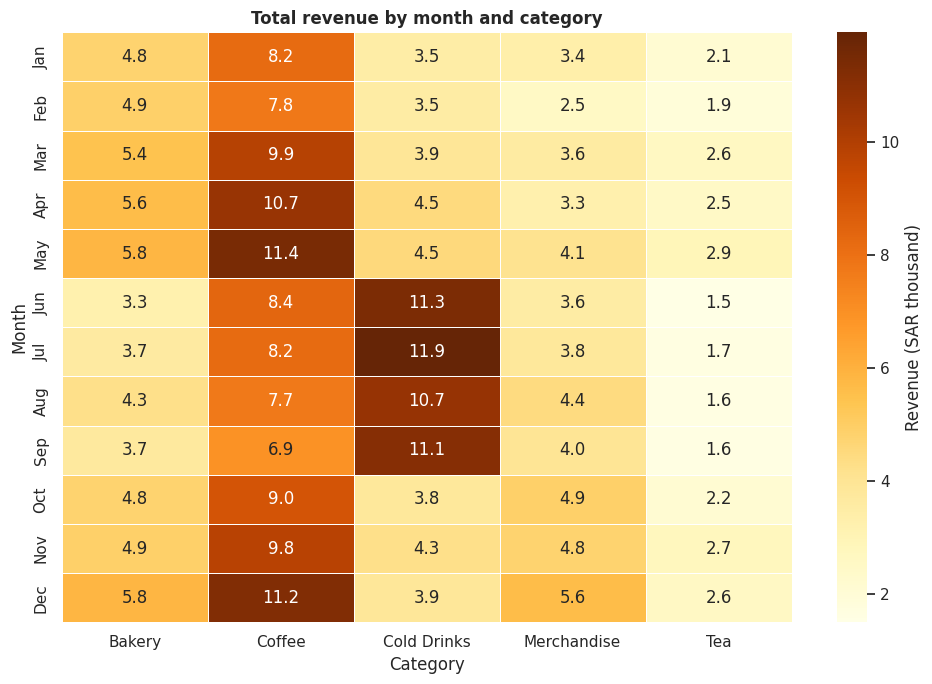

In [78]:
# YOUR CODE HERE
pv = df.pivot_table(values="revenue", index="month", columns="category", aggfunc="sum") / 1000
pv.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 7))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="YlOrBr", linewidths=0.5,
            cbar_kws={"label": "Revenue (SAR thousand)"})
plt.title("Total revenue by month and category")
plt.xlabel("Category")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

✍️ **Your answer:** *(write 2–4 sentences here — double-click to edit)*

### Task 4.3 — Correlation heat-map  *(3 pts)*
Compute the Pearson correlation matrix of `quantity, unit_price, discount, customer_age, prep_time_min, rating, revenue`
and plot a **lower-triangle** heat-map (mask the upper triangle) with a **diverging** colour map **centred at 0** (`vmin=-1, vmax=1`), annotated values, square cells.
Name the strongest positive and strongest negative pair (off-diagonal) in a markdown cell.

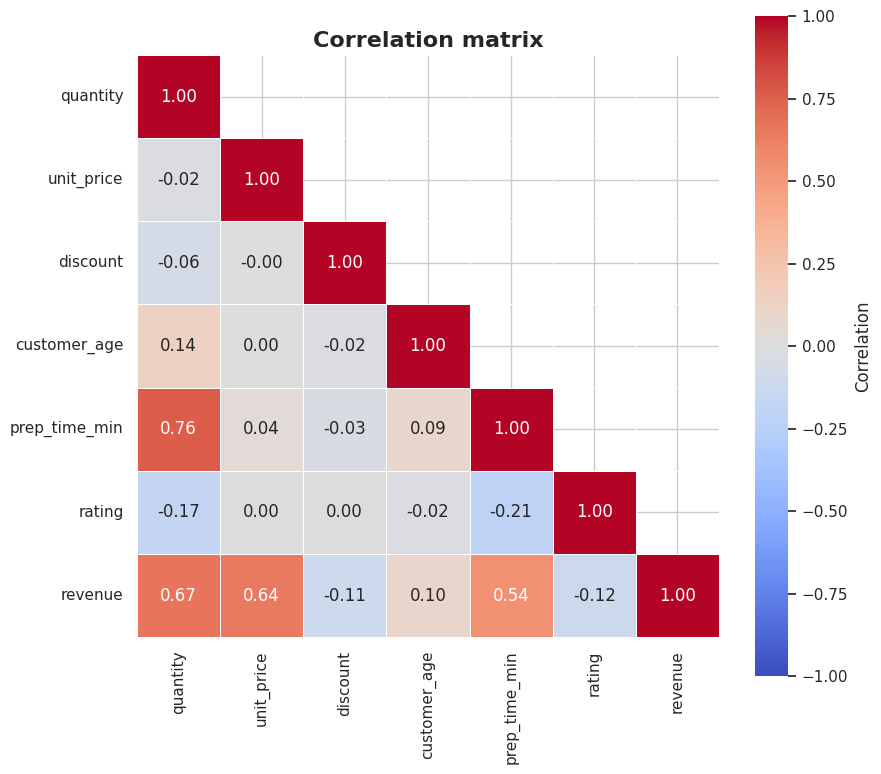

Strongest positive pair: ('prep_time_min', 'quantity') 0.7589401979891546
Strongest negative pair: ('rating', 'prep_time_min') -0.21162785304270784


In [79]:
# YOUR CODE HERE
cols = ["quantity", "unit_price", "discount", "customer_age", "prep_time_min", "rating", "revenue"]
corr = df[cols].corr(method="pearson")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # hide the upper triangle

plt.figure(figsize=(9, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"label": "Correlation"})
plt.title("Correlation matrix", fontsize=16)
plt.tight_layout()
plt.show()

# strongest pairs (off-diagonal, lower triangle only)
pairs = corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack().dropna()
print("Strongest positive pair:", pairs.idxmax(), pairs.max())
print("Strongest negative pair:", pairs.idxmin(), pairs.min())

✍️ **Your answer:** *(write 2–4 sentences here — double-click to edit)*

### Task 4.4 — Pair plot  *(2 pts)*
Use `sns.pairplot` on a **random sample of 600 rows** with variables `unit_price, quantity, prep_time_min, revenue`, `hue="category"`, a colour-blind palette, `corner=True`, semi-transparent points and a figure-level title.

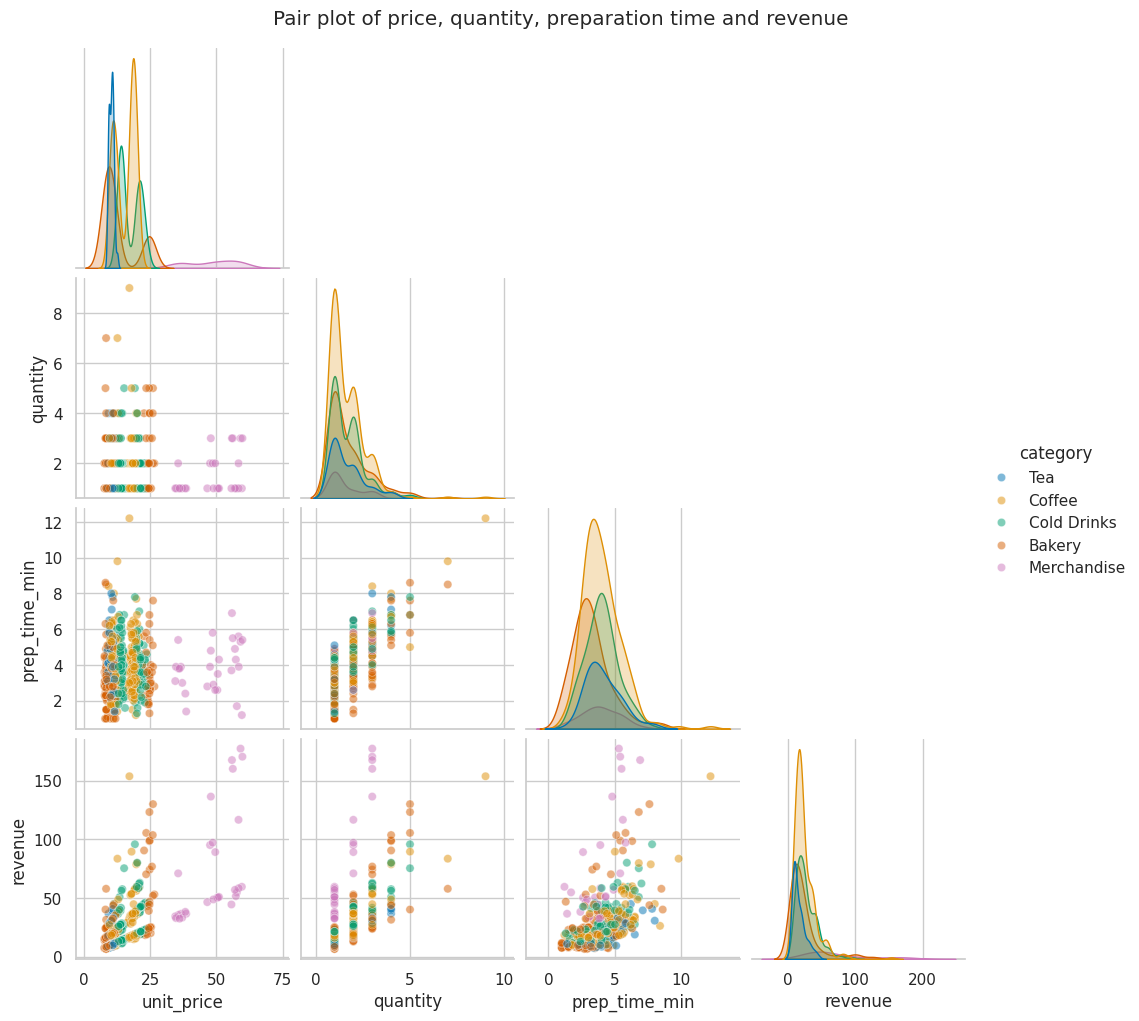

In [80]:
# YOUR CODE HERE
s600 = df.sample(600, random_state=SEED)

g = sns.pairplot(s600, vars=["unit_price", "quantity", "prep_time_min", "revenue"], hue="category",
                 palette="colorblind", corner=True, plot_kws={"alpha": 0.5})
g.fig.suptitle("Pair plot of price, quantity, preparation time and revenue", y=1.02)
plt.show()

### Task 4.5 — Combine Seaborn and Matplotlib customisation  *(2 pts)*
Draw a **Seaborn bar plot** of total revenue per `city` (sorted) and then use **Matplotlib** to:
* write the value (in SAR thousand) above every bar;
* add **one annotation with an arrow** pointing at the best city;
* create a **custom legend** (using `matplotlib.patches.Patch`) that explains *"Best city"* vs *"Other cities"* (colour the best bar differently);
* set custom font sizes for title, labels and ticks.

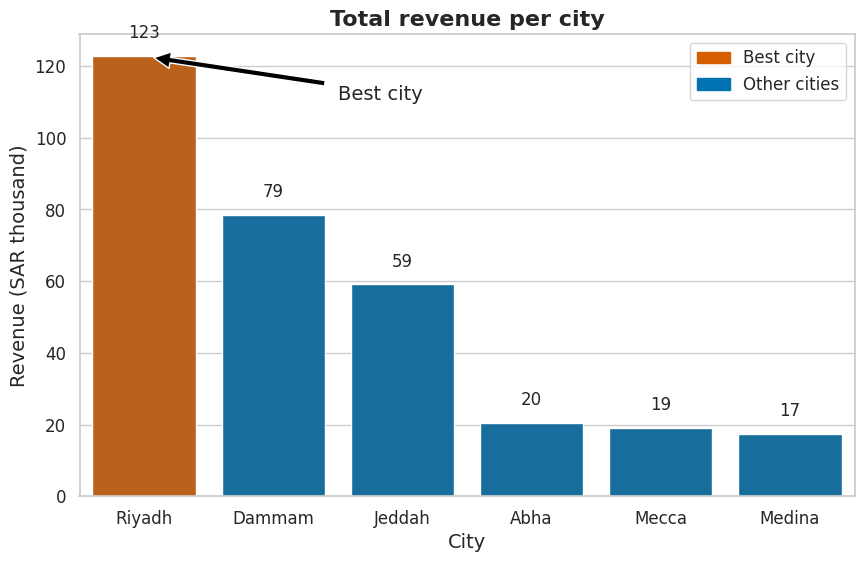

In [81]:
# YOUR CODE HERE
from matplotlib.patches import Patch

city_rev = df.groupby("city")["revenue"].sum().sort_values(ascending=False) / 1000
best = city_rev.index[0]

colors = []
for c in city_rev.index:
    if c == best:
        colors.append(PAL[3])
    else:
        colors.append(PAL[0])

plt.figure(figsize=(10, 6))
sns.barplot(x=city_rev.index, y=city_rev.values, palette=colors, hue=city_rev.index, legend=False)

# value above every bar
for i, v in enumerate(city_rev.values):
    plt.text(i, v + 5, f"{v:,.0f}", ha="center", fontsize=12)

# annotation with an arrow
plt.annotate("Best city", xy=(0, city_rev.values[0]), xytext=(1.5, city_rev.values[0] * 0.9),
             arrowprops=dict(facecolor="black", shrink=0.05), fontsize=14)

# custom legend
plt.legend(handles=[Patch(color=PAL[3], label="Best city"), Patch(color=PAL[0], label="Other cities")], fontsize=12)

plt.title("Total revenue per city", fontsize=16)
plt.xlabel("City", fontsize=14)
plt.ylabel("Revenue (SAR thousand)", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

---
# Part 5 · Exploratory Data Analysis: Correlation & PCA  *(8 pts)*
*Course topic 6: Pearson's r, principal component analysis.*

### Task 5.1 — Is slow service really hurting satisfaction?  *(2 pts)*
Compute **Pearson r** *and* **Spearman ρ** (with p-values) between `prep_time_min` and `rating`. Draw a `sns.regplot` on a 1 500-row sample (add a small `y_jitter` because rating is ordinal).
Explain in 2 sentences which coefficient is more appropriate here and what the result means.

Pearson r = -0.212, p-value = 2.0823016684913104e-121
Spearman rho = -0.192, p-value = 1.709404363969305e-99


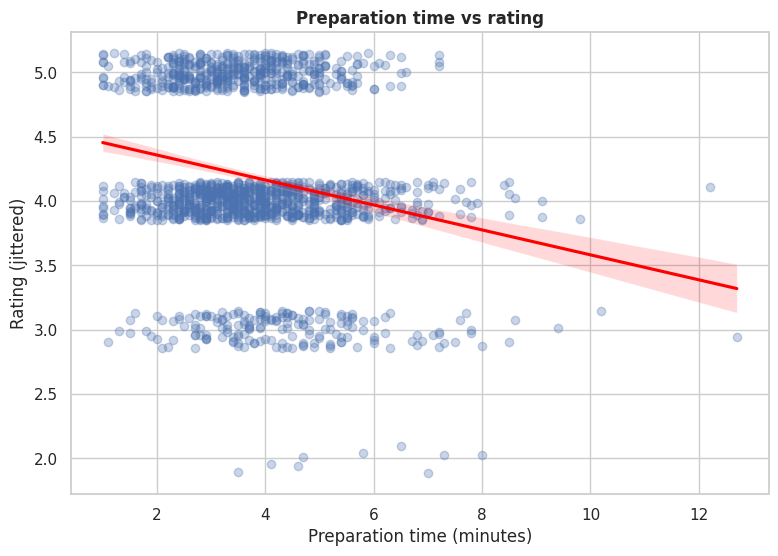

In [82]:
# YOUR CODE HERE
r, p_r = stats.pearsonr(df["prep_time_min"], df["rating"])
rho, p_rho = stats.spearmanr(df["prep_time_min"], df["rating"])
print(f"Pearson r = {r:.3f}, p-value = {p_r}")
print(f"Spearman rho = {rho:.3f}, p-value = {p_rho}")

s1500 = df.sample(1500, random_state=SEED)
plt.figure(figsize=(9, 6))
sns.regplot(x="prep_time_min", y="rating", data=s1500, y_jitter=0.15,
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Preparation time vs rating")
plt.xlabel("Preparation time (minutes)")
plt.ylabel("Rating (jittered)")
plt.show()

✍️ **Your answer:** *(write 2–4 sentences here — double-click to edit)*

### Task 5.2 — Principal Component Analysis  *(3 pts)*
1. Standardise `quantity, unit_price, discount, customer_age, prep_time_min, rating, revenue` (`StandardScaler`) — explain in a comment why scaling is necessary.
2. Fit **`pca = PCA()`** keeping **all** components.
3. Plot a **scree plot** (bars of explained-variance ratio) with the **cumulative** variance as a line and a dashed 80 % threshold.
4. Show the **loadings** of the first three PCs as an annotated heat-map (`pd.DataFrame(pca.components_[:3].T, index=features, columns=["PC1","PC2","PC3"])`).

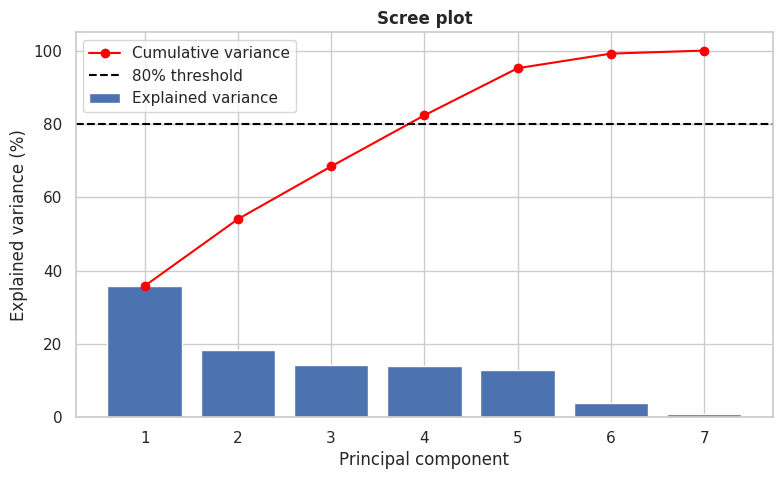

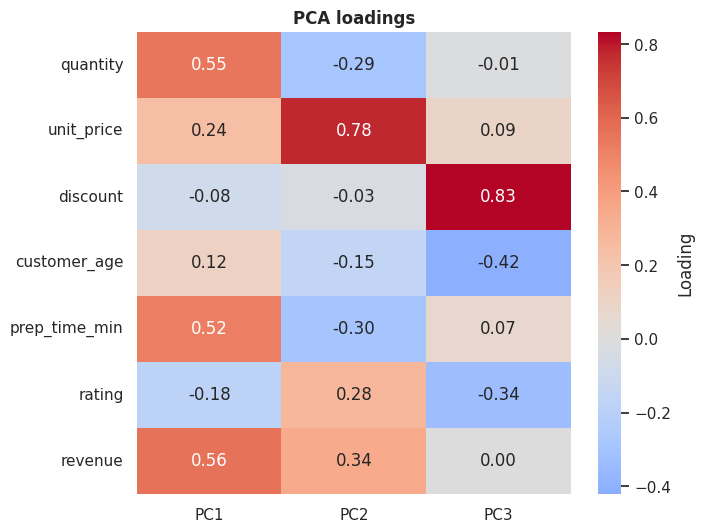

In [83]:
pca_features = ["quantity", "unit_price", "discount", "customer_age", "prep_time_min", "rating", "revenue"]
pca = None
# YOUR CODE HERE
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_features = ["quantity", "unit_price", "discount", "customer_age", "prep_time_min", "rating", "revenue"]

# Scaling is necessary because PCA looks for the directions with the largest variance.
# Without scaling, columns with large numbers (revenue) would dominate columns with small numbers (discount).
scaler = StandardScaler()
scaler.fit(df[pca_features])
X = scaler.transform(df[pca_features])

pca = PCA()          # keep all the components
pca.fit(X)

var_ratio = pca.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)
components = np.arange(1, len(var_ratio) + 1)

# scree plot
plt.figure(figsize=(9, 5))
plt.bar(components, var_ratio * 100, label="Explained variance")
plt.plot(components, cum_var * 100, marker="o", color="red", label="Cumulative variance")
plt.axhline(80, linestyle="--", color="black", label="80% threshold")
plt.title("Scree plot")
plt.xlabel("Principal component")
plt.ylabel("Explained variance (%)")
plt.legend()
plt.show()

# loadings of the first three components
loadings = pd.DataFrame(pca.components_[:3].T, index=pca_features, columns=["PC1", "PC2", "PC3"])
plt.figure(figsize=(7, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"label": "Loading"})
plt.title("PCA loadings")
plt.show()

### Task 5.3 — Project and interpret  *(3 pts)*
1. Scatter plot of the data on **PC1 vs PC2** (sample of 2 000 rows, coloured by `category`, axis labels showing the % variance explained).
2. Write 3–4 sentences: how many components do you need for ≥ 80 % variance? Which variables drive PC1 and PC2? Do categories separate in the PC space?

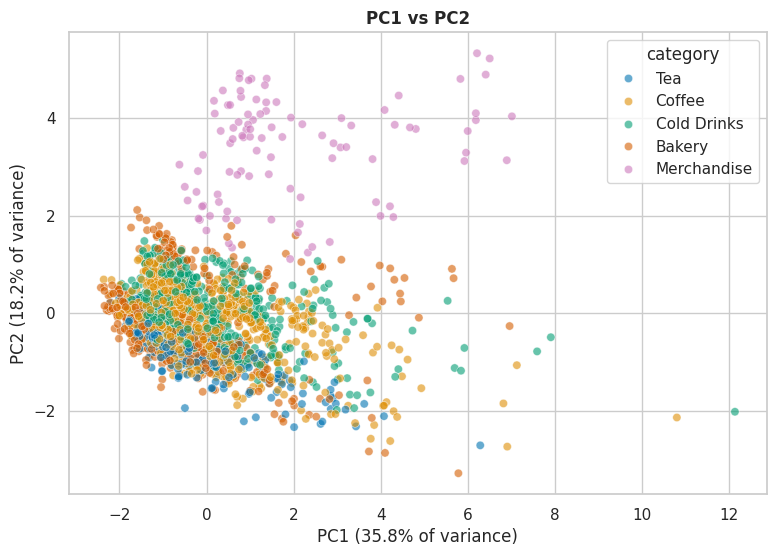

The variance captured by PC 1 is: 35.80%
The variance captured by PC 2 is: 18.23%
The variance captured by PC 3 is: 14.37%
The variance captured by PC 4 is: 13.93%
The variance captured by PC 5 is: 12.85%
The variance captured by PC 6 is: 3.98%
The variance captured by PC 7 is: 0.83%
Components needed for at least 80% of the variance: 4


,PC1,PC2,PC3
quantity,0.550,-0.290,-0.010
unit_price,0.240,0.780,0.090
discount,-0.080,-0.030,0.830
customer_age,0.120,-0.150,-0.420
prep_time_min,0.520,-0.300,0.070
rating,-0.180,0.280,-0.340
revenue,0.560,0.340,0.000


In [84]:
# YOUR CODE HERE
pcs = pca.transform(X)
df["pc1"] = pcs[:, 0]
df["pc2"] = pcs[:, 1]

sample = df.sample(2000, random_state=SEED)
plt.figure(figsize=(9, 6))
sns.scatterplot(x="pc1", y="pc2", hue="category", palette="colorblind", alpha=0.6, data=sample)
plt.title("PC1 vs PC2")
plt.xlabel(f"PC1 ({var_ratio[0] * 100:.1f}% of variance)")
plt.ylabel(f"PC2 ({var_ratio[1] * 100:.1f}% of variance)")
plt.show()

for ind, var in enumerate(var_ratio):
    print(f"The variance captured by PC {ind + 1} is: {var * 100:0.2f}%")
print("Components needed for at least 80% of the variance:", np.argmax(cum_var >= 0.8) + 1)
display(loadings.round(2))

✍️ **Your answer:** *(write 2–4 sentences here — double-click to edit)*

In [85]:
# 🔒 CHECK — Part 5 (given)
assert hasattr(pca, "explained_variance_ratio_") and np.isclose(pca.explained_variance_ratio_.sum(), 1.0), "fit PCA() with ALL components"
assert len(pca.explained_variance_ratio_) >= 5
print("✅ Part 5 checks passed")

✅ Part 5 checks passed


---
# Part 6 · Time-Series Visualization, Decomposition & Forecasting  *(14 pts)*
*Course topic 7: line/area/bar charts, moving averages, trend & seasonality, stationarity, forecasting.*

### Task 6.1 — Build and plot the daily series  *(3 pts)*
1. Create **`daily`**: total `revenue` per calendar day as a `pd.Series` with a **continuous daily `DatetimeIndex`** (`resample("D").sum()`), named `"revenue"`.
2. Plot it as a thin light line together with the **7-day** and **30-day rolling means** (`rolling().mean()`), with a legend, axis labels and a title.

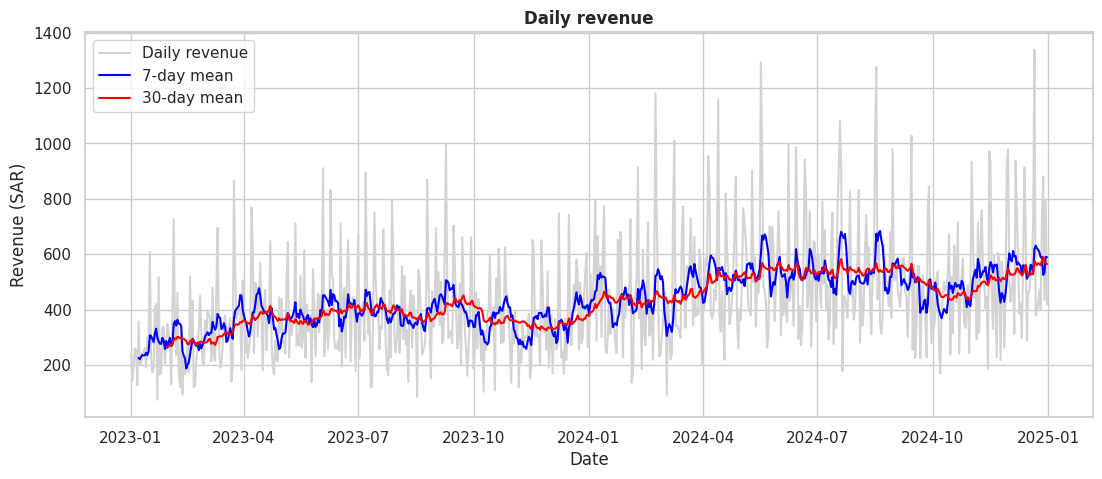

In [86]:
daily = None
# YOUR CODE HERE
daily = df.set_index("date")["revenue"].resample("D").sum()
daily.name = "revenue"

plt.figure(figsize=(13, 5))
plt.plot(daily.index, daily, color="lightgray", label="Daily revenue")
plt.plot(daily.index, daily.rolling(7).mean(), color="blue", label="7-day mean")
plt.plot(daily.index, daily.rolling(30).mean(), color="red", label="30-day mean")
plt.title("Daily revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (SAR)")
plt.legend()
plt.show()

In [87]:
# 🔒 CHECK — Part 6.1 (given)
assert isinstance(daily, pd.Series) and isinstance(daily.index, pd.DatetimeIndex)
assert len(daily) == 731 and daily.index.freqstr == "D", "daily must cover 2023-01-01 .. 2024-12-31 without gaps"
print("✅ daily series OK:", daily.index.min().date(), "→", daily.index.max().date())

✅ daily series OK: 2023-01-01 → 2024-12-31


### Task 6.2 — Monthly bar chart and stacked area chart  *(3 pts)*
In a `2 × 1` figure draw (a) a **bar chart** of monthly total revenue (`daily.resample("MS").sum()`), and (b) a **stacked area chart** of monthly revenue by `category`.
Use the same x-range in both panels (`sharex=True`) and format the dates on the x-axis.

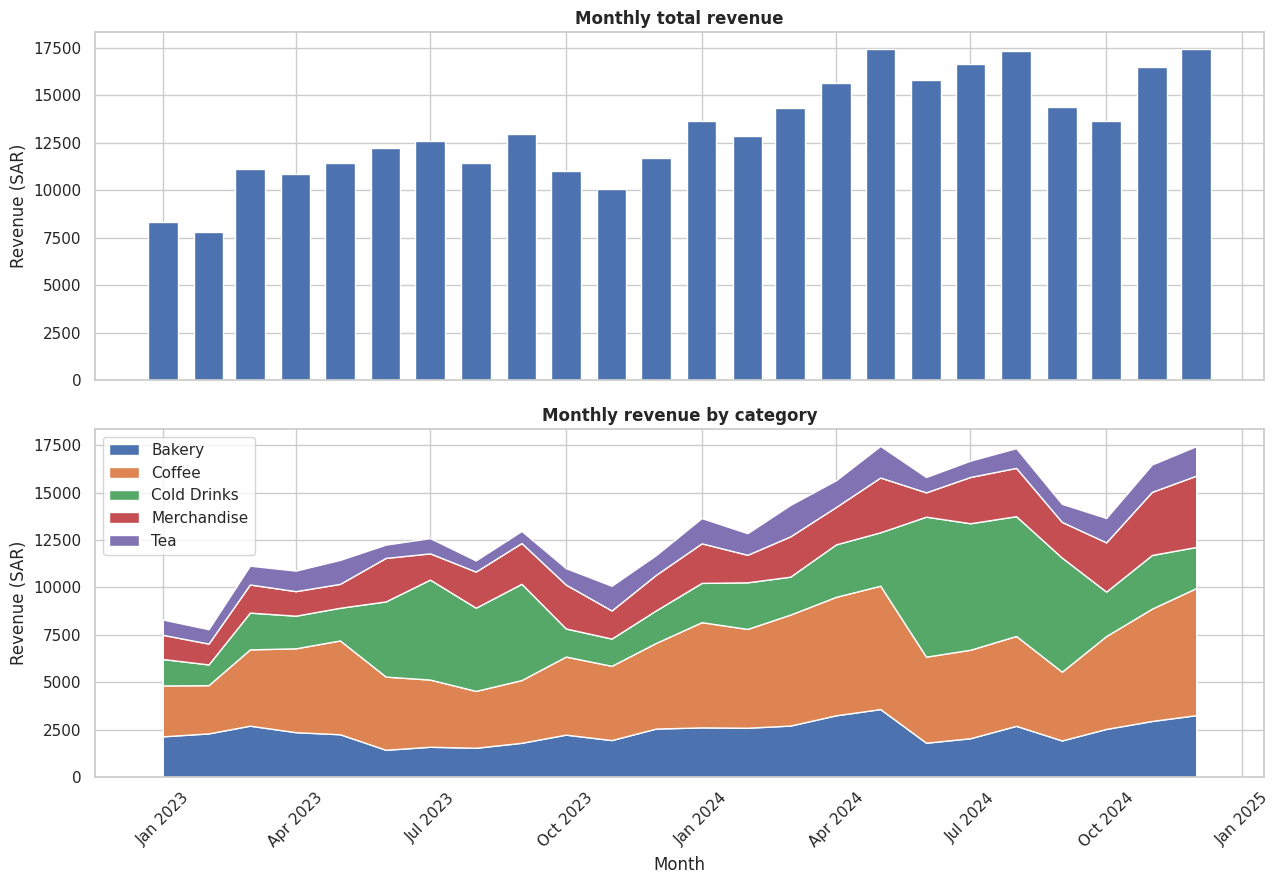

In [88]:
# YOUR CODE HERE
import matplotlib.dates as mdates

monthly = daily.resample("MS").sum()
monthly_cat = df.pivot_table(values="revenue", index=pd.Grouper(key="date", freq="MS"),
                             columns="category", aggfunc="sum")

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

axes[0].bar(monthly.index, monthly.values, width=20)
axes[0].set_title("Monthly total revenue")
axes[0].set_ylabel("Revenue (SAR)")

axes[1].stackplot(monthly_cat.index, monthly_cat.T.values, labels=monthly_cat.columns)
axes[1].set_title("Monthly revenue by category")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Revenue (SAR)")
axes[1].legend(loc="upper left")

axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Task 6.3 — Seasonal decomposition  *(3 pts)*
Apply `statsmodels.tsa.seasonal.seasonal_decompose` (**additive**, `period=7`) to `daily` and plot the four components (observed, trend, seasonal, residual).
Then compute the **average seasonal effect per weekday** (ordered Monday→Sunday) and the **overall trend growth** (2024 vs 2023 total revenue, in %), and interpret them.

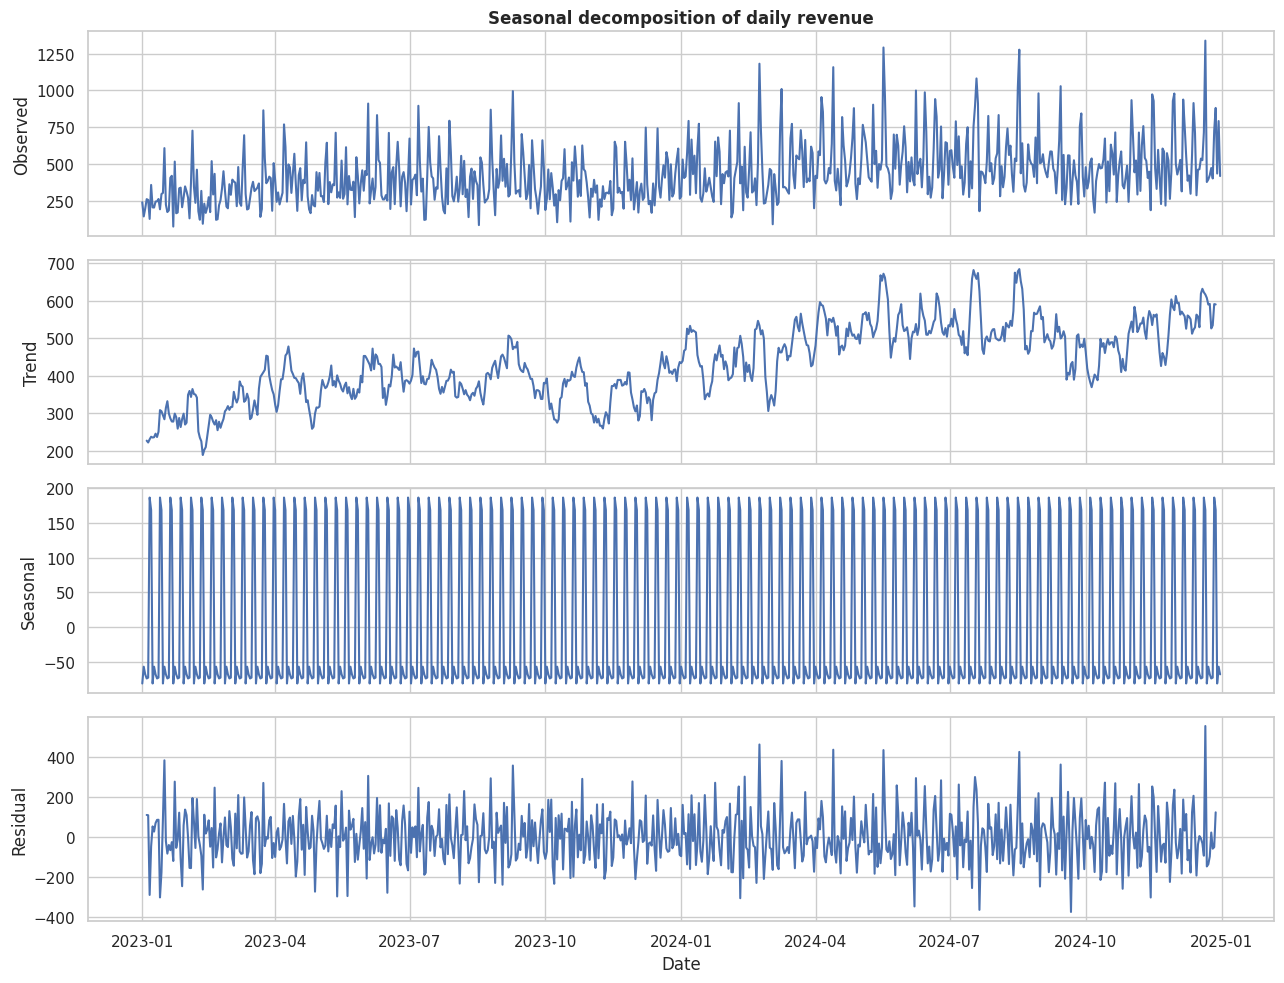

date
Monday      -57.475
Tuesday     -68.507
Wednesday   -74.454
Thursday    -73.230
Friday      186.692
Saturday    168.671
Sunday      -81.697
Name: seasonal, dtype: float64
Growth 2024 vs 2023: 41.1%


In [89]:
# YOUR CODE HERE
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(daily, model="additive", period=7)

fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
axes[0].plot(result.observed)
axes[0].set_ylabel("Observed")
axes[0].set_title("Seasonal decomposition of daily revenue")
axes[1].plot(result.trend)
axes[1].set_ylabel("Trend")
axes[2].plot(result.seasonal)
axes[2].set_ylabel("Seasonal")
axes[3].plot(result.resid)
axes[3].set_ylabel("Residual")
axes[3].set_xlabel("Date")
plt.tight_layout()
plt.show()

# average seasonal effect per weekday
seasonal = result.seasonal
effect = seasonal.groupby(seasonal.index.day_name()).mean()
effect = effect.reindex(WEEKDAY_ORDER)
print(effect)

# overall growth 2024 vs 2023
rev_2023 = daily[daily.index.year == 2023].sum()
rev_2024 = daily[daily.index.year == 2024].sum()
print(f"Growth 2024 vs 2023: {(rev_2024 - rev_2023) / rev_2023 * 100:.1f}%")

✍️ **Your answer:** *(write 2–4 sentences here — double-click to edit)*

### Task 6.4 — Stationarity and differencing  *(2 pts)*
1. Run the **Augmented Dickey-Fuller** test (`statsmodels.tsa.stattools.adfuller`) on `daily` and on its **first difference** (`daily.diff().dropna()`).
2. Plot both series (`2 × 1`) and put the ADF p-value in each title.
3. Explain what a **stationary** series is and which series is stationary at α = 0.05.

ADF p-value of daily: 0.32855542442993235
ADF p-value of first difference: 1.8262877124999704e-19


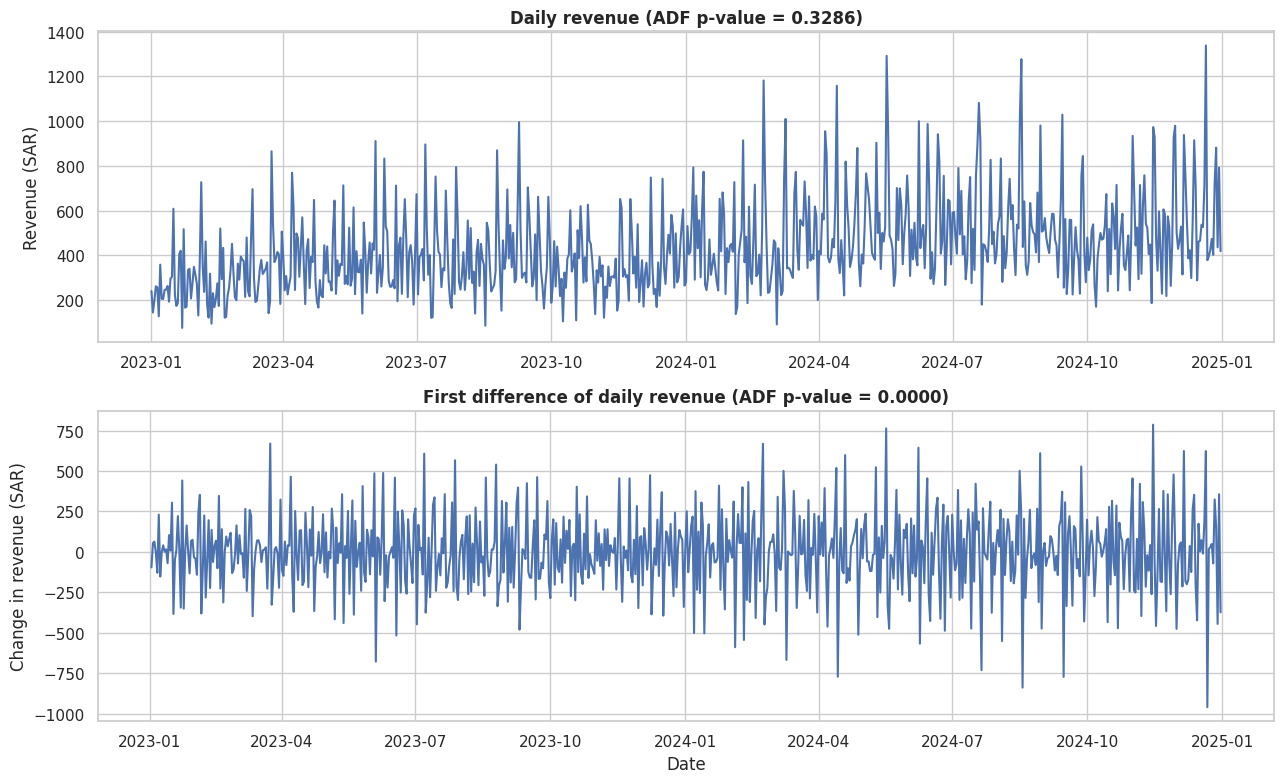

In [90]:
# YOUR CODE HERE
from statsmodels.tsa.stattools import adfuller

daily_diff = daily.diff().dropna()

p_daily = adfuller(daily)[1]
p_diff = adfuller(daily_diff)[1]
print("ADF p-value of daily:", p_daily)
print("ADF p-value of first difference:", p_diff)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
axes[0].plot(daily)
axes[0].set_title(f"Daily revenue (ADF p-value = {p_daily:.4f})")
axes[0].set_ylabel("Revenue (SAR)")
axes[1].plot(daily_diff)
axes[1].set_title(f"First difference of daily revenue (ADF p-value = {p_diff:.4f})")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Change in revenue (SAR)")
plt.tight_layout()
plt.show()

✍️ **Your answer:** *(write 2–4 sentences here — double-click to edit)*

### Task 6.5 — Forecast the next 28 days  *(3 pts)*
1. Hold out the **last 28 days** as a test set (`train`, `test`).
2. Fit a **Holt-Winters** model (`ExponentialSmoothing`, additive trend, additive seasonality, `seasonal_periods=7`) on `train` and store the 28-day forecast in **`forecast_hw`** (a Series with the test index).
3. Build a **seasonal-naive baseline** `forecast_naive`: repeat the last 7 observed days four times (same test index).
4. Create `metrics`: a DataFrame with index `["Holt-Winters", "Seasonal naive"]` and columns `["MAE", "MAPE (%)"]` computed on the test set.
5. Plot the last 60 training days, the actual test values and both forecasts; mention the better model and its error in the title or a text note.

,MAE,MAPE (%)
Holt-Winters,104.046,17.762
Seasonal naive,129.215,23.258


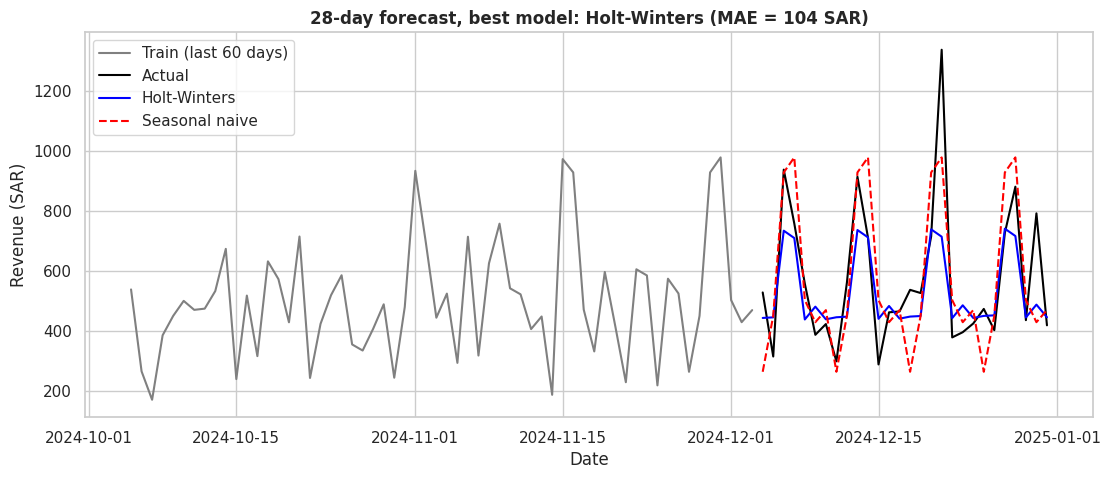

In [91]:
H = 28
forecast_hw = None
forecast_naive = None
metrics = None
# YOUR CODE HERE
from statsmodels.tsa.holtwinters import ExponentialSmoothing

H = 28
train = daily[:-H]
test = daily[-H:]

# Holt-Winters
model = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=7).fit()
forecast_hw = model.forecast(H)
forecast_hw.index = test.index

# seasonal naive: repeat the last 7 days four times
forecast_naive = pd.Series(list(train[-7:]) * 4, index=test.index)

# errors
mae_hw = np.mean(np.abs(test - forecast_hw))
mae_naive = np.mean(np.abs(test - forecast_naive))
mape_hw = np.mean(np.abs((test - forecast_hw) / test)) * 100
mape_naive = np.mean(np.abs((test - forecast_naive) / test)) * 100

metrics = pd.DataFrame({"MAE": [mae_hw, mae_naive], "MAPE (%)": [mape_hw, mape_naive]},
                       index=["Holt-Winters", "Seasonal naive"])
display(metrics)

plt.figure(figsize=(13, 5))
plt.plot(train[-60:], label="Train (last 60 days)", color="gray")
plt.plot(test, label="Actual", color="black")
plt.plot(forecast_hw, label="Holt-Winters", color="blue")
plt.plot(forecast_naive, label="Seasonal naive", color="red", linestyle="--")
best = metrics["MAE"].idxmin()
plt.title(f"28-day forecast, best model: {best} (MAE = {metrics['MAE'].min():.0f} SAR)")
plt.xlabel("Date")
plt.ylabel("Revenue (SAR)")
plt.legend()
plt.show()

In [92]:
# 🔒 CHECK — Part 6.5 (given)
assert len(forecast_hw) == len(forecast_naive) == 28
assert list(metrics.index) == ["Holt-Winters", "Seasonal naive"] and list(metrics.columns) == ["MAE", "MAPE (%)"]
assert (metrics > 0).all().all()
print("✅ Part 6 checks passed")

✅ Part 6 checks passed


---
# Part 7 · Interactive Visualization with Plotly  *(10 pts)*
*Course topic 5: Plotly Express, graph objects, animation, subplots, hover, range sliders.*
All figures must have a title, axis titles and informative **hover** text. Show them with `fig.show()`.

### Task 7.1 — Interactive bubble chart  *(2 pts)*
Aggregate by `category` and `product` (average price, total units, total revenue, average rating) and create a `px.scatter`: x = average price, y = total units, **bubble size = revenue**, colour = category, `hover_name` = product, extra `hover_data` (avg rating, revenue formatted).

In [93]:
# YOUR CODE HERE
prod = df.groupby(["category", "product"]).agg(avg_price=("unit_price", "mean"),
                                               total_units=("quantity", "sum"),
                                               total_revenue=("revenue", "sum"),
                                               avg_rating=("rating", "mean")).reset_index()
prod["revenue_text"] = prod["total_revenue"].map(lambda x: f"{x:,.0f} SAR")

fig = px.scatter(prod, x="avg_price", y="total_units", size="total_revenue", color="category",
                 hover_name="product", hover_data=["avg_rating", "revenue_text"],
                 color_discrete_sequence=px.colors.qualitative.Safe,
                 title="Price vs units sold (bubble size = revenue)")
fig.update_layout(xaxis_title="Average price (SAR)", yaxis_title="Total units sold")
fig.show()

### Task 7.2 — Animated bar chart  *(3 pts)*
Create an **animated** `px.bar` of monthly revenue per category: x = `category`, y = revenue, `animation_frame="year_month"`, colour = category.
Fix the y-axis range to the global maximum (so bars are comparable between frames) and make sure the **play button and slider** are visible.

In [94]:
# YOUR CODE HERE
anim = df.groupby(["year_month", "category"])["revenue"].sum().reset_index()
y_max = anim["revenue"].max() * 1.1

fig = px.bar(anim, x="category", y="revenue", color="category", animation_frame="year_month",
             range_y=[0, y_max], color_discrete_sequence=px.colors.qualitative.Safe,
             title="Monthly revenue per category")
fig.update_layout(xaxis_title="Category", yaxis_title="Revenue (SAR)")
fig.show()

### Task 7.3 — Dual-axis chart  *(2 pts)*
With `plotly.subplots.make_subplots(specs=[[{"secondary_y": True}]])` plot **monthly revenue as bars** (primary axis) and the **monthly average rating as a line with markers** (secondary axis, range 3–5).
Label both y-axes, use a unified hover (`hovermode="x unified"`).

In [95]:
# YOUR CODE HERE
monthly = df.groupby("year_month").agg(revenue=("revenue", "sum"), rating=("rating", "mean")).reset_index()

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=monthly["year_month"], y=monthly["revenue"], name="Revenue"), secondary_y=False)
fig.add_trace(go.Scatter(x=monthly["year_month"], y=monthly["rating"], name="Average rating",
                         mode="lines+markers"), secondary_y=True)
fig.update_layout(title="Monthly revenue and average rating", xaxis_title="Month", hovermode="x unified")
fig.update_yaxes(title_text="Revenue (SAR)", secondary_y=False)
fig.update_yaxes(title_text="Average rating", range=[3, 5], secondary_y=True)
fig.show()

### Task 7.4 — Geographic bubble map  *(2 pts)*
Compute total revenue per store (`store_id`, `city`, `store_size`, `lat`, `lon`) and draw a `px.scatter_geo` (or `px.scatter_map`) with bubble size = revenue, colour = store size and hover showing store id, city and revenue. Zoom to the stores (`fitbounds="locations"`).

In [96]:
# YOUR CODE HERE
store_rev = df.groupby(["store_id", "city", "store_size", "lat", "lon"])["revenue"].sum().reset_index()

fig = px.scatter_geo(store_rev, lat="lat", lon="lon", size="revenue", color="store_size",
                     hover_name="store_id", hover_data=["city", "revenue"],
                     title="Total revenue per store")
fig.update_geos(fitbounds="locations")
fig.show()

### Task 7.5 — Range slider and standalone HTML  *(1 pt)*
Plot `daily` revenue as an interactive line (`px.line`) with a **range slider** and **range-selector buttons** (1 m, 6 m, all), then export it with `fig.write_html("outputs/daily_revenue_interactive.html", include_plotlyjs="cdn")`.

In [97]:
# YOUR CODE HERE
fig = px.line(daily.reset_index(), x="date", y="revenue", title="Daily revenue")
fig.update_layout(xaxis_title="Date", yaxis_title="Revenue (SAR)")
fig.update_xaxes(rangeslider_visible=True,
                 rangeselector=dict(buttons=[
                     dict(count=1, label="1m", step="month", stepmode="backward"),
                     dict(count=6, label="6m", step="month", stepmode="backward"),
                     dict(step="all", label="All")]))
fig.write_html("outputs/daily_revenue_interactive.html", include_plotlyjs="cdn")
fig.show()

---
# Part 8 · Data Storytelling & Reflection  *(10 pts)*
*All topics — communicating insights effectively.*

### Task 8.1 — One story figure  *(4 pts)*
Design **one publication-quality figure** that communicates the **single most important insight** you found, for a non-technical manager. It must have:
* a **headline title that states the finding** (not just "Revenue by month"), and a subtitle/source note;
* **direct annotations** or highlighted regions instead of heavy gridlines/legends;
* a colour-blind-safe palette, minimal chart junk, readable fonts (≥ 11 pt);
* saved as `outputs/story_figure.png` (300 dpi).

*(Suggestion used in the reference solution: share of monthly revenue of **Cold Drinks vs Coffee** with summer months shaded — but you may choose any insight you can defend.)*

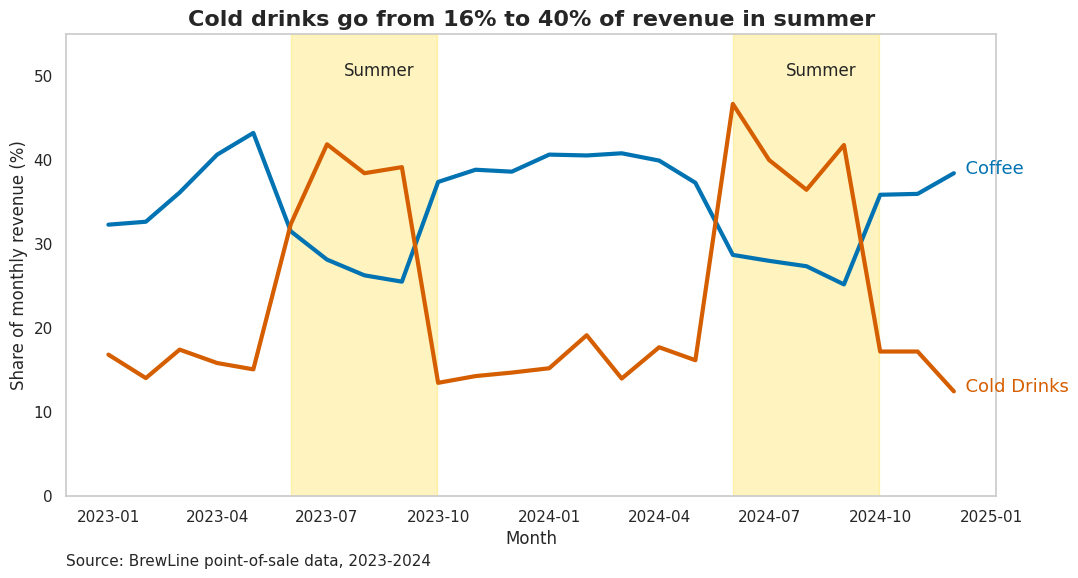

In [98]:
# YOUR CODE HERE  (finish with: fig.savefig("outputs/story_figure.png", dpi=300, bbox_inches="tight"))
# share of Cold Drinks and Coffee in the monthly revenue
monthly_cat = df.pivot_table(values="revenue", index="year_month", columns="category", aggfunc="sum")
share = monthly_cat.div(monthly_cat.sum(axis=1), axis=0) * 100
dates = pd.to_datetime(share.index + "-01")

# summer months (June to September)
summer = dates.month.isin([6, 7, 8, 9])
cold_summer = share.loc[summer, "Cold Drinks"].mean()
cold_other = share.loc[~summer, "Cold Drinks"].mean()

fig, ax = plt.subplots(figsize=(12, 6))

# shade the summer months
for year in [2023, 2024]:
    ax.axvspan(pd.Timestamp(f"{year}-06-01"), pd.Timestamp(f"{year}-09-30"), color="gold", alpha=0.25)
    ax.text(pd.Timestamp(f"{year}-07-15"), 50, "Summer", fontsize=12)

ax.plot(dates, share["Coffee"], color=PAL[0], linewidth=3)
ax.plot(dates, share["Cold Drinks"], color=PAL[3], linewidth=3)

# direct labels instead of a legend
ax.text(dates[-1], share["Coffee"].iloc[-1], "  Coffee", color=PAL[0], fontsize=13)
ax.text(dates[-1], share["Cold Drinks"].iloc[-1], "  Cold Drinks", color=PAL[3], fontsize=13)

ax.set_title(f"Cold drinks go from {cold_other:.0f}% to {cold_summer:.0f}% of revenue in summer", fontsize=16, fontweight="bold")
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Share of monthly revenue (%)", fontsize=12)
ax.text(0, -0.15, "Source: BrewLine point-of-sale data, 2023-2024", transform=ax.transAxes, fontsize=11)
ax.set_ylim(0, 55)
ax.grid(False)

fig.savefig("outputs/story_figure.png", dpi=300, bbox_inches="tight")
plt.show()

### Task 8.2 — Three insights and two recommendations  *(4 pts)*
In the Markdown cell below write **three insights** (each supported by a **specific number from your analysis** and a reference to the figure/task where it appears) and **two concrete recommendations** for BrewLine management.
Insights must be *findings*, not descriptions ("Riyadh earns 41 % of revenue" ✔, "I made a bar chart" ✘).

✍️ **Your insights and recommendations**

**Insight 1: Cold drinks sell much more in summer. They are about 40% of revenue from June to September, but only about 16% in the other months (Task 8.1 figure and Task 4.2 heat-map).

**Insight 2: Weekends are busier. Average daily revenue is about 613 SAR on Friday and Saturday, and about 363 SAR on the other days (Task 4.1 and Task 2.4).

**Insight 3: Slow orders get lower ratings. The correlation between preparation time and rating is r = -0.21 (Task 5.1). Orders under 3 minutes average a rating of 4.30, and orders over 7 minutes average 3.67.

**Recommendation 1:Add more staff on Fridays and Saturdays so orders are prepared faster and ratings stay high.

**Recommendation 2:Buy more cold drink ingredients and run cold drink offers from June to September. Focus on coffee offers in the other months

### Task 8.3 — Reflection  *(2 pts)*
In **4–6 sentences** answer: (a) Which **two charts** from this project were the most effective and why? (b) Name **one chart you would *not* use again** (or one design mistake you corrected). (c) What are **two limitations** of the data/analysis (e.g. simulated data, outlier removal choices, imputation, forecast horizon) and how could they mislead a decision-maker?

✍️ **Your reflection: The most useful charts were the dashboard in Task 4.1 and the story figure in Task 8.1. The dashboard shows the weekend peak and the monthly trend together, and the story figure shows the summer change clearly with only two lines. I would not use the pair plot again, because the points overlap and it is hard to read. One limitation is that the data is simulated, so real customers may act differently. Another is that I filled the missing ratings with the median, which makes ratings look more similar than they really are, so a manager could trust the satisfaction numbers too much.

---
## ✅ Final submission checklist
- [ ] Name and ID filled in at the top
- [ ] *Kernel → Restart & Run All* finishes without errors and no `YOUR CODE HERE` stubs remain
- [ ] All 🔒 check cells print ✅
- [ ] Every figure has title, axis labels, readable fonts and an accessible palette
- [ ] Every "interpret / explain" question is answered **with numbers**
- [ ] `outputs/` contains: `brewline_clean.csv`, `fig_3_categorical.png`, `daily_revenue_interactive.html`, `story_figure.png`
- [ ] Notebook (with outputs) + `outputs/` folder zipped and submitted

*Good luck — and remember: a chart is only as good as the decision it helps someone make.* ☕

In [99]:
# 🔒 FINAL SELF-CHECK (given)
required = ["outputs/brewline_clean.csv", "outputs/fig_3_categorical.png", "outputs/daily_revenue_interactive.html", "outputs/story_figure.png"]
for f in required:
    print(("✅" if os.path.exists(f) else "❌ MISSING"), f)
print("Student:", STUDENT_NAME, STUDENT_ID)

✅ outputs/brewline_clean.csv
✅ outputs/fig_3_categorical.png
✅ outputs/daily_revenue_interactive.html
✅ outputs/story_figure.png
Student:  
